# Apollo Hospitals: Appointment No-Show and Patient Engagement Analysis

**Milestone Project 4 | Exploratory Data Analysis in Python**
**Name:** Shubham Paitwar

---

## Objective

Apollo runs in-clinic, video and home-visit consultations across 15 cities, and a good chunk of booked appointments never turn into a completed visit. In this notebook I go through the appointment data to understand how bookings are trending, where no-shows are coming from, whether reminders and loyalty actually help, and what all of this means in rupees. The last section pulls the findings together into recommendations.

## Data used

- `apollo_appointments_fact.csv`: 75,000 appointments, 52 columns (one row per appointment)
- `apollo_doctors_dim.csv`: 320 doctors, 15 columns (joined on `doctor_id` where needed)

## Rules I followed while analysing

- Wait time, satisfaction, consultation duration and utilisation exist only for **Completed** rows, so those analyses are filtered to Completed.
- Revenue columns are zero for non-Completed rows, so revenue analysis is scoped to Completed (except the no-show loss estimate, which uses the listed consultation fee).
- `None` in chronic condition, membership type, insurance provider and cancellation reason means "not applicable", not a missing value.

## Contents

1. Loading the data and basic checks
2. Business overview
3. No-show analysis
4. Reminder and engagement effectiveness
5. Patient and demographic segmentation
6. Financial performance
7. Doctor utilisation and service quality
8. Key findings and recommendations

## 1. Loading the Data and Basic Checks

Importing the libraries and reading both files. The appointments table is stored as `df1` and the doctors table as `doctors_df`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

folder = r"D:\wsCube\Apollo Hospital Project Data\OneDrive_2026-09-30\apollo hospitals - Python Project"

# First table
df1 = pd.read_csv(folder + r"\apollo_appointments_fact.csv")

# Second table
doctors_df = pd.read_csv(folder + r"\apollo_doctors_dim.csv")

# Display both tables separately
print("Appointments Table:")
display(df1.head())

print("Doctors Table:")
display(doctors_df.head())


Appointments Table:


,appointment_id,patient_id,doctor_id,appointment_date,appointment_day,appointment_day_of_week,appointment_month,appointment_quarter,appointment_year,appointment_hour,...,insurance_coverage,insurance_provider,insurance_covered_amount,patient_out_of_pocket,revenue_realized,payment_mode,wait_time_minutes,consultation_duration_min,patient_satisfaction_score,doctor_utilization_pct
0,APPT5000001,PAT117608,DOC1035,2023-11-15,Wednesday,2,11,Q4,2023,15,...,No,NaN,0,2700,2700,UPI,11.0,40.0,4.8,84.2
1,APPT5000002,PAT128732,DOC1049,2023-03-13,Monday,0,3,Q1,2023,9,...,No,NaN,0,1400,1400,UPI,21.0,18.0,4.1,64.5
2,APPT5000003,PAT137532,DOC1033,2022-02-07,Monday,0,2,Q1,2022,17,...,No,NaN,0,600,600,Net Banking,6.0,6.0,5.0,75.6
3,APPT5000004,PAT113284,DOC1288,2023-11-20,Monday,0,11,Q4,2023,17,...,No,NaN,0,1275,1275,UPI,2.0,25.0,4.4,68.6
4,APPT5000005,PAT107443,DOC1064,2024-02-02,Friday,4,2,Q1,2024,19,...,No,NaN,0,1700,1700,Cash,7.0,13.0,3.5,67.7


Doctors Table:


,doctor_id,doctor_name,specialty,qualification,experience_years,city,state,hospital_name,consultation_fee,rating,total_reviews,available_days,avg_slot_duration_min,accepts_insurance,teleconsult_enabled
0,DOC1001,Dr. Deepa Sharma,Urology,"MBBS, MCh",12,Bengaluru,Karnataka,Apollo Hospital Bannerghatta,2300,4.4,1502,Mon-Fri,15,Yes,No
1,DOC1002,Dr. Venkatesan Khan,Paediatrics,"MBBS, MS, FRCS",25,Chandigarh,Punjab,Apollo Clinic Sector 8,1200,4.5,2453,Mon-Sat,10,Yes,Yes
2,DOC1003,Dr. Pradeep Menon,General Physician,"MBBS, DM",13,Mumbai,Maharashtra,Apollo Clinic Andheri,700,4.7,995,Mon-Wed-Fri-Sat,15,No,No
3,DOC1004,Dr. Vivek Mathew,General Physician,"MBBS, MD",31,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,1000,4.9,666,Mon-Wed-Fri-Sat,20,Yes,Yes
4,DOC1005,Dr. Savita Philip,General Physician,"MBBS, MD, PhD",5,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,600,4.5,1383,Mon-Sat,30,Yes,Yes


Quick sanity checks on data types and duplicate keys before doing anything else.

In [2]:
df1.dtypes

appointment_id                    str
patient_id                        str
doctor_id                         str
appointment_date                  str
appointment_day                   str
appointment_day_of_week         int64
appointment_month               int64
appointment_quarter               str
appointment_year                int64
appointment_hour                int64
appointment_minute              int64
time_slot                         str
time_of_day                       str
booking_date                      str
booking_lead_days               int64
booking_channel                   str
appointment_type                  str
specialty                         str
city                              str
state                             str
hospital_name                     str
patient_age                     int64
age_group                         str
patient_gender                    str
patient_city_tier               int64
patient_chronic_condition         str
apollo_membe

In [3]:
doctors_df.dtypes


doctor_id                    str
doctor_name                  str
specialty                    str
qualification                str
experience_years           int64
city                         str
state                        str
hospital_name                str
consultation_fee           int64
rating                   float64
total_reviews              int64
available_days               str
avg_slot_duration_min      int64
accepts_insurance            str
teleconsult_enabled          str
dtype: object

In [4]:
doctors_df["doctor_id"].duplicated().sum()

np.int64(0)

In [5]:
df1["appointment_id"].duplicated().sum()

np.int64(0)

In [6]:
print(df1.columns.tolist())

['appointment_id', 'patient_id', 'doctor_id', 'appointment_date', 'appointment_day', 'appointment_day_of_week', 'appointment_month', 'appointment_quarter', 'appointment_year', 'appointment_hour', 'appointment_minute', 'time_slot', 'time_of_day', 'booking_date', 'booking_lead_days', 'booking_channel', 'appointment_type', 'specialty', 'city', 'state', 'hospital_name', 'patient_age', 'age_group', 'patient_gender', 'patient_city_tier', 'patient_chronic_condition', 'apollo_member', 'membership_type', 'reminder_type', 'reminders_sent', 'patient_prior_visits', 'patient_prior_no_shows', 'is_first_visit', 'repeat_visit', 'visit_reason', 'appointment_status', 'no_show', 'no_show_flag', 'cancellation_reason', 'consultation_fee', 'discount_pct', 'actual_fee_charged', 'insurance_coverage', 'insurance_provider', 'insurance_covered_amount', 'patient_out_of_pocket', 'revenue_realized', 'payment_mode', 'wait_time_minutes', 'consultation_duration_min', 'patient_satisfaction_score', 'doctor_utilization_p

**What the checks tell me**

- `appointment_date` and `booking_date` are read in as text, so the date has to be converted to datetime before any time-series work.
- No duplicates in `appointment_id` or `doctor_id` (both counts are 0). That means each row is one unique appointment and the doctors table has one row per doctor, so joining on `doctor_id` will not create extra rows.
- `no_show_flag` is already a clean 0/1 column, which makes no-show rates easy to calculate with a simple sum / count.

---
## 2. Business Overview

### Q1. How is appointment volume trending across months and quarters from 2022 to 2024?

In [7]:


# Convert appointment date to datetime
df1["appointment_date"] = pd.to_datetime(
    df1["appointment_date"], errors="coerce"
)

# Filter data from 2022 to 2024
df = df1[
    df1["appointment_date"].between("2022-01-01", "2024-12-31")
].copy()

# Monthly appointment volume
monthly = (
    df.set_index("appointment_date")
      .resample("MS")
      .size()
)

print(monthly)

appointment_date
2022-01-01    2426
2022-02-01    2012
2022-03-01    2085
2022-04-01    1926
2022-05-01    2033
2022-06-01    1823
2022-07-01    1833
2022-08-01    1835
2022-09-01    2115
2022-10-01    2206
2022-11-01    2299
2022-12-01    2275
2023-01-01    2371
2023-02-01    2013
2023-03-01    2103
2023-04-01    1964
2023-05-01    2002
2023-06-01    1896
2023-07-01    1884
2023-08-01    1785
2023-09-01    2038
2023-10-01    2278
2023-11-01    2329
2023-12-01    2391
2024-01-01    2427
2024-02-01    2078
2024-03-01    2033
2024-04-01    2024
2024-05-01    2013
2024-06-01    1862
2024-07-01    1862
2024-08-01    1832
2024-09-01    2083
2024-10-01    2291
2024-11-01    2225
2024-12-01    2348
Freq: MS, dtype: int64


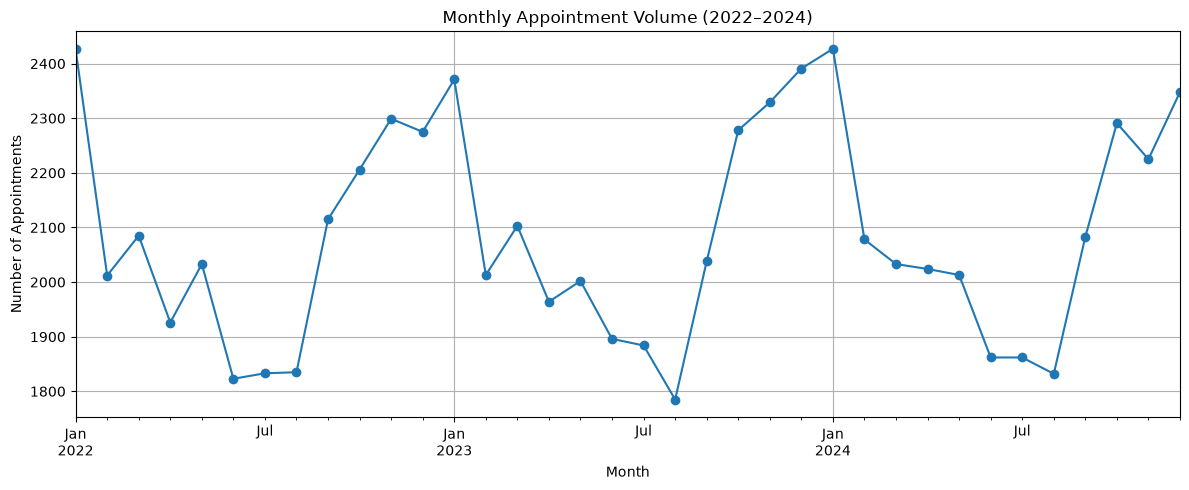

In [8]:
monthly.plot(figsize=(12, 5), marker="o")

plt.title("Monthly Appointment Volume (2022–2024)")
plt.xlabel("Month")
plt.ylabel("Number of Appointments")
plt.grid(True)
plt.tight_layout()
plt.show()

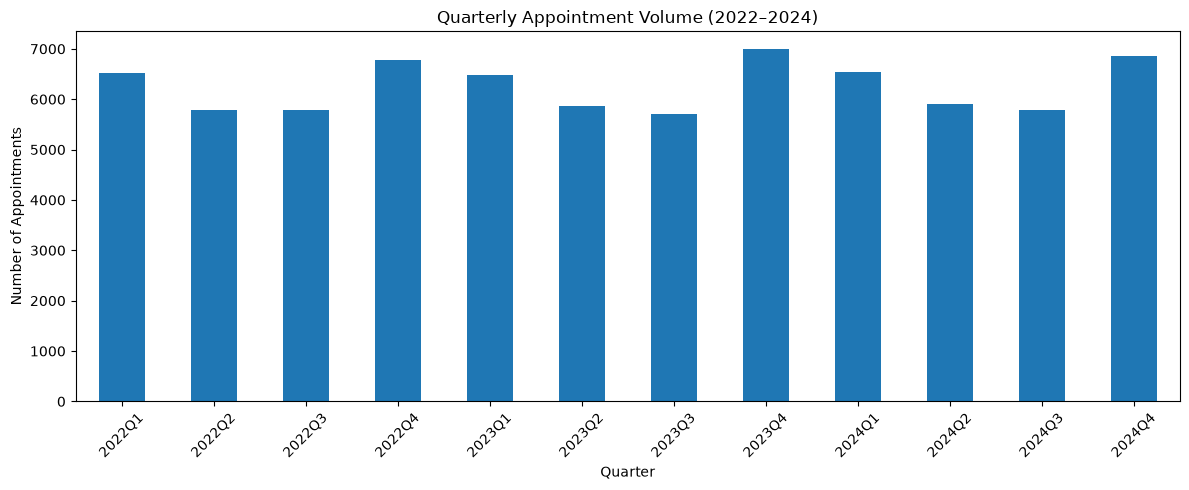

In [9]:
# Calculate quarterly appointment volume
quarterly = (
    df.set_index("appointment_date")
      .resample("QS")
      .size()
)

# Convert quarterly dates into readable labels
quarterly.index = quarterly.index.to_period("Q").astype(str)

# Plot the chart
quarterly.plot(kind="bar", figsize=(12, 5))

plt.title("Quarterly Appointment Volume (2022–2024)")
plt.xlabel("Quarter")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observations**

- Total volume across the three years is 75,000 appointments. Yearly totals are 24,868 (2022), 25,054 (2023) and 25,078 (2024), so growth is almost flat, under 1% a year.
- The seasonal shape is the same in all three years. Q4 is the busiest quarter (roughly 6,800 to 7,000 appointments) and Q2 and Q3 are the slowest (roughly 5,700 to 5,900).
- Monthly numbers peak around December and January (highest is January 2024 at 2,427) and sink in June to August (lowest is August 2023 at 1,785).
- So demand is predictable rather than growing. Capacity and staffing can be planned around the winter peak, and the summer dip is the natural window for outreach campaigns.

### Q2. What is the split of outcomes across completed, no-show, cancelled and scheduled appointments?

,Appointment_Count,Percentage
appointment_status,,
Completed,55275,73.70
No-Show,11584,15.45
Cancelled,5793,7.72
Scheduled,2348,3.13


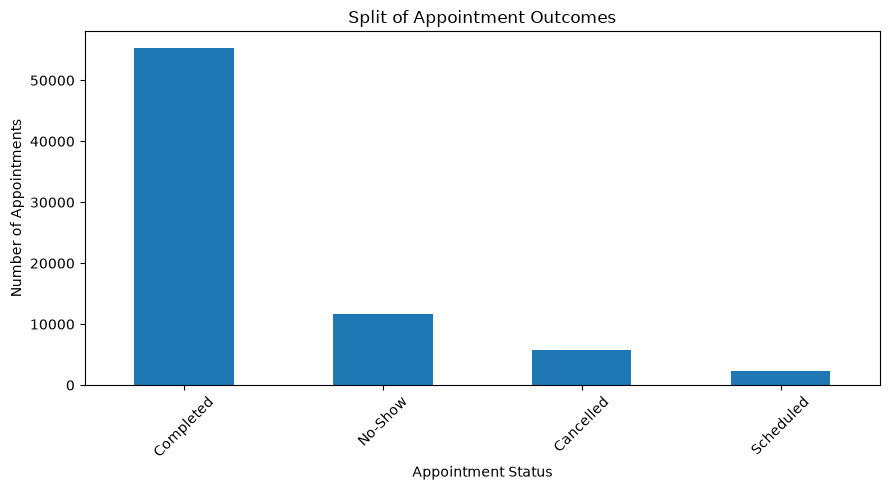

In [10]:
import pandas as pd

# Count appointments by status
outcome_counts = df1['appointment_status'].value_counts()

# Calculate percentage split
outcome_percentage = (
    df1['appointment_status']
    .value_counts(normalize=True) * 100
)

# Create summary table
outcome_summary = pd.DataFrame({
    'Appointment_Count': outcome_counts,
    'Percentage': outcome_percentage.round(2)
})

display(outcome_summary)

import matplotlib.pyplot as plt

outcome_summary['Appointment_Count'].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Split of Appointment Outcomes')
plt.xlabel('Appointment Status')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



**Observations**

- Completed: 55,275 (73.70%), No-Show: 11,584 (15.45%), Cancelled: 5,793 (7.72%), Scheduled: 2,348 (3.13%).
- No-shows are about twice as common as cancellations. A cancellation at least gives the hospital a chance to reuse the slot, whereas a no-show leaves the doctor sitting idle, so this is the bigger problem.
- Scheduled appointments are still pending and don't have an outcome yet.

### Q3. Which booking channels drive the highest volume and how does the channel mix look?

,Booking_Channel,Appointment_Count,Percentage_Share
0,Apollo App,34042,45.39
1,Website,18545,24.73
2,Call Centre,11201,14.93
3,Walk-In,7501,10.00
4,Partner App,3711,4.95


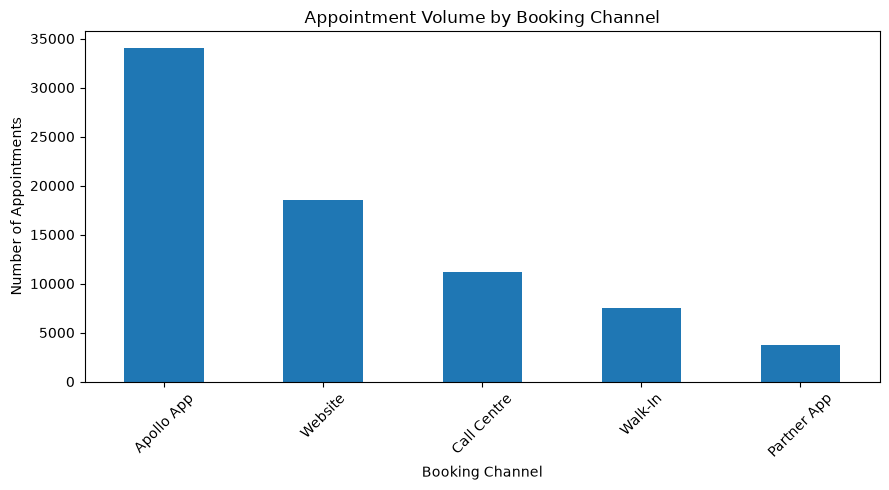

In [11]:
# Which booking channels drive the highest volume and how does the channel mix look? 


# Count appointments by booking channel
channel_summary = (
    df1['booking_channel']
    .value_counts()
    .reset_index()
)

# Rename columns
channel_summary.columns = ['Booking_Channel', 'Appointment_Count']

# Calculate percentage share
channel_summary['Percentage_Share'] = (
    channel_summary['Appointment_Count']
    / channel_summary['Appointment_Count'].sum() * 100
).round(2)

# Sort by highest volume
channel_summary = channel_summary.sort_values(
    by='Appointment_Count',
    ascending=False
)

# Display summary table
display(channel_summary)

# Plot appointment volume
channel_summary.plot(
    x='Booking_Channel',
    y='Appointment_Count',
    kind='bar',
    figsize=(9, 5),
    legend=False
)

plt.title('Appointment Volume by Booking Channel')
plt.xlabel('Booking Channel')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observations**

- The Apollo App is the biggest channel by a distance with 34,042 bookings (45.39%), followed by the Website (24.73%) and the Call Centre (14.93%).
- Walk-in is 10.00% and Partner Apps are only 4.95%.
- App, website and partner apps together make up roughly 75% of bookings, so the business is already mostly digital. That also means digital reminders are a practical way to reach most patients.

---
## 3. No-Show Analysis

### Q1. Which specialties and cities have the highest and lowest no-show rates?

In [12]:
# Which specialties and cities have the highest and lowest no-show rates? 

print(df1['no_show'].value_counts(dropna=False))
print(df1['no_show_flag'].value_counts(dropna=False))




df = df1.copy()

# Function to calculate no-show rate
def calculate_noshow_rate(group_column):
    result = (
        df.groupby(group_column)
        .agg(
            Total_Appointments=('appointment_id', 'count'),
            No_Shows=('no_show_flag', 'sum')
        )
        .reset_index()
    )

    result['No_Show_Rate (%)'] = (
        result['No_Shows'] / result['Total_Appointments'] * 100
    ).round(2)

    return result.sort_values(
        'No_Show_Rate (%)', ascending=False
    )

# No-show rates by specialty
specialty_noshow = calculate_noshow_rate('specialty')

# No-show rates by city
city_noshow = calculate_noshow_rate('city')

print("No-show rate by specialty:")
display(specialty_noshow)

print("No-show rate by city:")
display(city_noshow)


print("Highest no-show rate — Specialty")
display(specialty_noshow.head(1))

print("Lowest no-show rate — Specialty")
display(specialty_noshow.tail(1))

print("Highest no-show rate — City")
display(city_noshow.head(1))

print("Lowest no-show rate — City")
display(city_noshow.tail(1))

no_show
No     61068
Yes    11584
NaN     2348
Name: count, dtype: int64
no_show_flag
0    63416
1    11584
Name: count, dtype: int64
No-show rate by specialty:


,specialty,Total_Appointments,No_Shows,No_Show_Rate (%)
11,Psychiatry,2989,711,23.79
1,Dermatology,7824,1608,20.55
2,ENT,5385,988,18.35
3,Endocrinology,2087,355,17.01
8,Ophthalmology,3193,503,15.75
5,General Physician,20272,3049,15.04
12,Pulmonology,2624,394,15.02
9,Orthopaedics,5589,810,14.49
4,Gastroenterology,2621,377,14.38
13,Urology,2287,320,13.99


No-show rate by city:


,city,Total_Appointments,No_Shows,No_Show_Rate (%)
12,Lucknow,3100,516,16.65
13,Mumbai,10043,1659,16.52
6,Delhi,10757,1754,16.31
2,Bhopal,2078,336,16.17
11,Kolkata,5872,933,15.89
10,Kochi,2776,438,15.78
9,Jaipur,2736,429,15.68
0,Ahmedabad,3585,561,15.65
7,Hyderabad,7439,1160,15.59
1,Bengaluru,8627,1287,14.92


Highest no-show rate — Specialty


...

,specialty,Total_Appointments,No_Shows,No_Show_Rate (%)
7,Neurology,4993,515,10.31


Highest no-show rate — City


,city,Total_Appointments,No_Shows,No_Show_Rate (%)
12,Lucknow,3100,516,16.65


Lowest no-show rate — City


,city,Total_Appointments,No_Shows,No_Show_Rate (%)
14,Pune,4141,533,12.87


**Observations**

- **Specialty:** Psychiatry has the highest no-show rate at 23.79%, followed by Dermatology (20.55%) and ENT (18.35%). Neurology is the lowest at 10.31%, with Paediatrics next at 11.85%.
- **City:** Lucknow is highest at 16.65% (Mumbai 16.52% and Delhi 16.31% are close behind) and Pune is lowest at 12.87%.
- The gap between best and worst specialty is about 13.5 percentage points, while the gap between best and worst city is only about 3.8. Specialty clearly matters more than location.
- Volume matters too. General Physician has only an average rate (15.04%) but it is the biggest specialty, so it produces the most no-shows in absolute terms (3,049), with Dermatology second (1,608).

### Q2. How does booking lead time affect the probability of a no-show?

,Lead_Time_Group,Total_Appointments,No_Shows,No_Show_Rate (%)
0,Same day,20810,3193,15.34
1,1–3 days,26302,3651,13.88
2,4–7 days,16442,2623,15.95
3,8–14 days,9030,1648,18.25
4,15–30 days,2416,469,19.41
5,Over 30 days,0,0,NaN


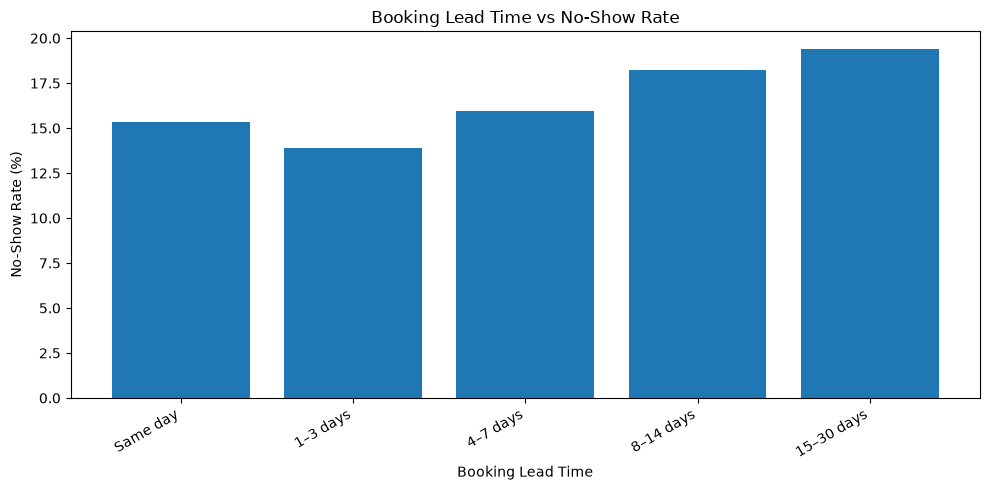

In [13]:


df = df1.copy()

# Create booking lead-time groups
bins = [-1, 0, 3, 7, 14, 30, float('inf')]
labels = [
    'Same day',
    '1–3 days',
    '4–7 days',
    '8–14 days',
    '15–30 days',
    'Over 30 days'
]

df['Lead_Time_Group'] = pd.cut(
    df['booking_lead_days'],
    bins=bins,
    labels=labels
)

# Calculate appointment volume and no-show rate
lead_time_analysis = (
    df.groupby('Lead_Time_Group', observed=False)
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

lead_time_analysis['No_Show_Rate (%)'] = (
    lead_time_analysis['No_Shows']
    / lead_time_analysis['Total_Appointments'] * 100
).round(2)

display(lead_time_analysis)


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    lead_time_analysis['Lead_Time_Group'].astype(str),
    lead_time_analysis['No_Show_Rate (%)']
)

plt.title('Booking Lead Time vs No-Show Rate')
plt.xlabel('Booking Lead Time')
plt.ylabel('No-Show Rate (%)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Observations**

- Bookings made 1 to 3 days ahead have the lowest no-show rate (13.88%). Same-day bookings are slightly higher at 15.34%.
- After the first week the rate climbs steadily: 4 to 7 days is 15.95%, 8 to 14 days is 18.25% and 15 to 30 days is 19.41%.
- A booking made two to four weeks ahead is about 5.5 percentage points more likely to be a no-show than one made 1 to 3 days ahead.
- There are no bookings beyond 30 days in this data, which is why the last row is empty.

### Q3. Do evening slots, weekends and longer-lead bookings see higher dropout?

In [14]:
# Do evening slots, weekends, and longer-lead bookings see higher dropout? 


df = df1.copy()

# Convert relevant columns to numeric where needed
df['no_show_flag'] = pd.to_numeric(
    df['no_show_flag'], errors='coerce'
)

# Normalize text columns
df['time_of_day'] = df['time_of_day'].astype('string').str.strip()

# Identify evening appointments
df['Slot_Type'] = np.where(
    df['time_of_day'].str.lower().eq('evening'),
    'Evening',
    'Other times'
)

slot_analysis = (
    df.dropna(subset=['no_show_flag'])
    .groupby('Slot_Type', observed=False)
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

slot_analysis['No_Show_Rate (%)'] = (
    slot_analysis['No_Shows']
    / slot_analysis['Total_Appointments'] * 100
).round(2)

display(slot_analysis)

,Slot_Type,Total_Appointments,No_Shows,No_Show_Rate (%)
0,Evening,15045,2673,17.77
1,Other times,59955,8911,14.86


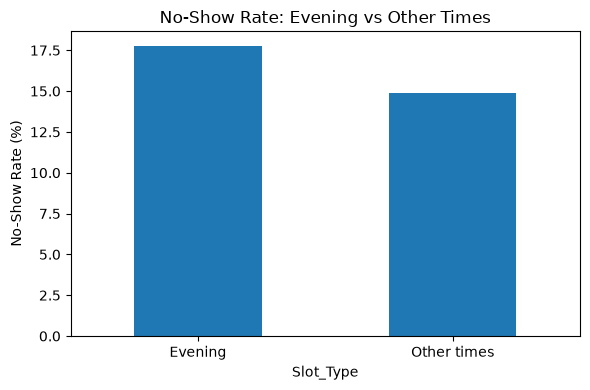

In [15]:
slot_analysis.plot(
    x='Slot_Type', y='No_Show_Rate (%)',
    kind='bar', legend=False, figsize=(6, 4)
)
plt.title('No-Show Rate: Evening vs Other Times')
plt.ylabel('No-Show Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Now weekends vs weekdays. I first looked at how `appointment_day_of_week` is stored (it is a number, 0 to 6), so the weekend flag is derived from the actual appointment date instead.

appointment_day_of_week
6    10930
3    10759
1    10715
2    10710
5    10703
0    10598
4    10585
Name: count, dtype: int64


,Day_Type,Total_Appointments,No_Shows,No_Show_Rate (%)
0,Weekday,53367,7676,14.38
1,Weekend,21633,3908,18.06


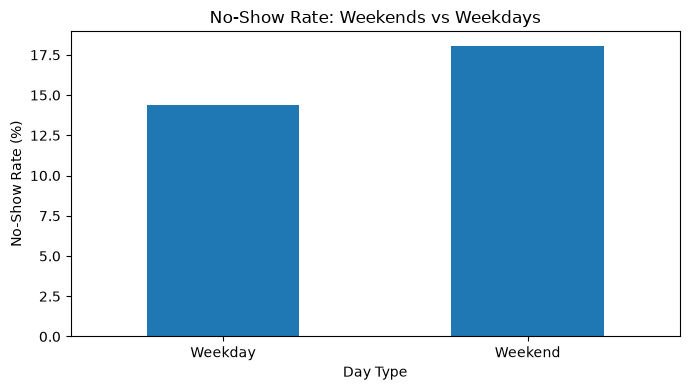

In [16]:

print(
    df1['appointment_day_of_week']
    .value_counts(dropna=False)
)



df = df1.copy()

# Convert appointment_date to datetime
df['appointment_date'] = pd.to_datetime(
    df['appointment_date'], errors='coerce'
)

# Derive weekday from the actual date
df['Day_Type'] = np.where(
    df['appointment_date'].dt.dayofweek >= 5,
    'Weekend',
    'Weekday'
)

# Calculate appointment counts and no-show rates
weekend_analysis = (
    df.dropna(subset=['appointment_date', 'no_show_flag'])
    .groupby('Day_Type')
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

weekend_analysis['No_Show_Rate (%)'] = (
    weekend_analysis['No_Shows']
    / weekend_analysis['Total_Appointments'] * 100
).round(2)

display(weekend_analysis)


weekend_analysis.plot(
    x='Day_Type',
    y='No_Show_Rate (%)',
    kind='bar',
    legend=False,
    figsize=(7, 4)
)

plt.title('No-Show Rate: Weekends vs Weekdays')
plt.xlabel('Day Type')
plt.ylabel('No-Show Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observations**

- **Evening slots:** 17.77% no-show vs 14.86% for all other times of day, about 2.9 points higher. Evening is about a fifth of all appointments (15,045).
- **Weekends:** 18.06% vs 14.38% on weekdays, about 3.7 points higher. Weekends carry a large share of the load (21,633 appointments).
- **Longer lead:** already shown in Q2 above. Bookings made 8 days or more ahead sit at 18.25% to 19.41%, compared with 13.88% to 15.95% for bookings within a week.
- So all three have higher dropout. Weekend is the strongest of the slot-related effects, then evening, and lead time beyond a week is the strongest of all.

### Q4. Which appointment types and booking channels carry the most no-show risk?

In [17]:
# Which appointment types and booking channels carry the most no-show risk?

df = df1.copy()

# Calculate no-show rate by appointment type
type_analysis = (
    df.groupby('appointment_type')
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

type_analysis['No_Show_Rate (%)'] = (
    type_analysis['No_Shows']
    / type_analysis['Total_Appointments'] * 100
).round(2)

type_analysis = type_analysis.sort_values(
    'No_Show_Rate (%)', ascending=False
)

display(type_analysis)



,appointment_type,Total_Appointments,No_Shows,No_Show_Rate (%)
0,Home Visit,10070,2557,25.39
2,Video Consult,15833,3232,20.41
1,In-Clinic,49097,5795,11.80


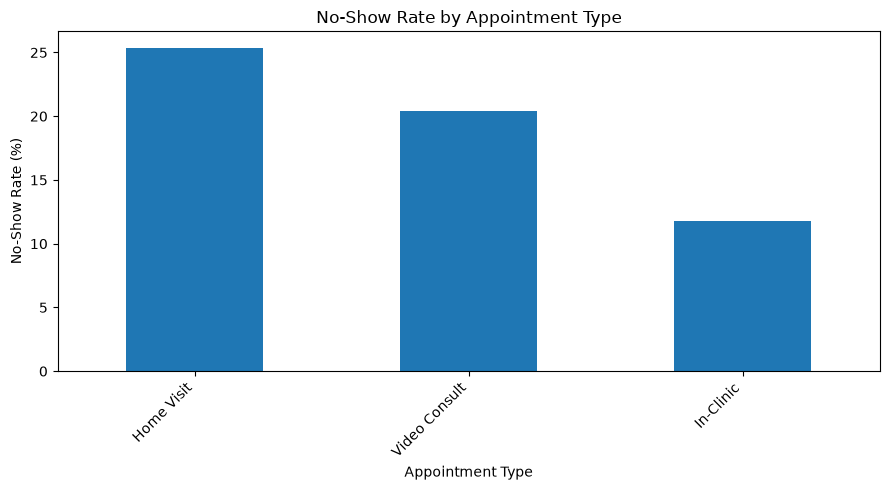

In [18]:
type_analysis.plot(
    x='appointment_type',
    y='No_Show_Rate (%)',
    kind='bar',
    figsize=(9, 5),
    legend=False
)

plt.title('No-Show Rate by Appointment Type')
plt.xlabel('Appointment Type')
plt.ylabel('No-Show Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [19]:
# Calculate no-show rate by booking channel
channel_analysis = (
    df.groupby('booking_channel')
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

channel_analysis['No_Show_Rate (%)'] = (
    channel_analysis['No_Shows']
    / channel_analysis['Total_Appointments'] * 100
).round(2)

channel_analysis = channel_analysis.sort_values(
    'No_Show_Rate (%)', ascending=False
)

display(channel_analysis)

,booking_channel,Total_Appointments,No_Shows,No_Show_Rate (%)
3,Walk-In,7501,1520,20.26
2,Partner App,3711,651,17.54
4,Website,18545,3090,16.66
1,Call Centre,11201,1650,14.73
0,Apollo App,34042,4673,13.73


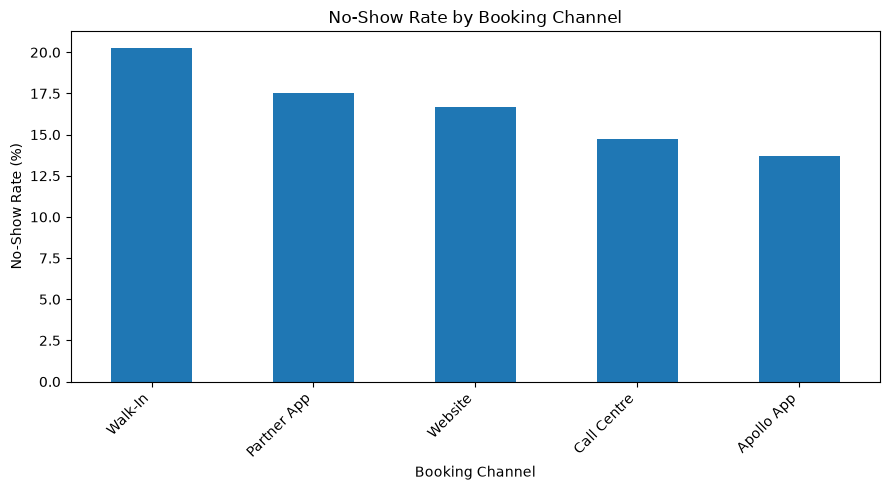

In [20]:
channel_analysis.plot(
    x='booking_channel',
    y='No_Show_Rate (%)',
    kind='bar',
    figsize=(9, 5),
    legend=False
)

plt.title('No-Show Rate by Booking Channel')
plt.xlabel('Booking Channel')
plt.ylabel('No-Show Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [21]:
print("Highest-risk appointment type:")
display(type_analysis.head(1))

print("Lowest-risk appointment type:")
display(type_analysis.tail(1))

print("Highest-risk booking channel:")
display(channel_analysis.head(1))

print("Lowest-risk booking channel:")
display(channel_analysis.tail(1))

Highest-risk appointment type:


,appointment_type,Total_Appointments,No_Shows,No_Show_Rate (%)
0,Home Visit,10070,2557,25.39


Lowest-risk appointment type:


,appointment_type,Total_Appointments,No_Shows,No_Show_Rate (%)
1,In-Clinic,49097,5795,11.8


Highest-risk booking channel:


,booking_channel,Total_Appointments,No_Shows,No_Show_Rate (%)
3,Walk-In,7501,1520,20.26


Lowest-risk booking channel:


,booking_channel,Total_Appointments,No_Shows,No_Show_Rate (%)
0,Apollo App,34042,4673,13.73


**Observations**

- **Appointment type:** Home Visit is the riskiest at 25.39%, Video Consult is next at 20.41% and In-Clinic is the safest at 11.80%.
- Home visits are only 13.4% of appointments but about 22% of all no-shows. Video consults are about 21% of appointments but nearly 28% of no-shows. In-clinic is about 65% of appointments and around half of the no-shows.
- **Booking channel:** Walk-In is the highest at 20.26%, then Partner App (17.54%) and Website (16.66%). Call Centre is 14.73% and the Apollo App is the lowest at 13.73%.
- It is interesting that walk-in bookings do worst. One possible reason is that a walk-in booking is made at the counter for a later slot and then nobody follows up with the patient. That is worth checking with the operations team.
- The Apollo App is both the largest channel and the best-performing one, so pushing bookings there has a double benefit.

---
## 4. Reminder and Engagement Effectiveness

### Q1. How much does reminder type reduce no-show rates compared to no-reminder patients?

In [22]:
# Reminder and Engagement Effectiveness 



df = df1.copy()

reminder_analysis = (
    df.groupby('reminder_type', dropna=False)
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

reminder_analysis['No_Show_Rate (%)'] = (
    reminder_analysis['No_Shows']
    / reminder_analysis['Total_Appointments'] * 100
).round(2)

display(
    reminder_analysis.sort_values(
        'No_Show_Rate (%)', ascending=False
    )
)

,reminder_type,Total_Appointments,No_Shows,No_Show_Rate (%)
0,No Reminder,11321,3311,29.25
3,SMS Only,14988,2363,15.77
1,SMS + WhatsApp,26101,3414,13.08
2,SMS + WhatsApp + Call,22590,2496,11.05


In [23]:
reminder_count_analysis = (
    df.groupby('reminders_sent', dropna=False)
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

reminder_count_analysis['No_Show_Rate (%)'] = (
    reminder_count_analysis['No_Shows']
    / reminder_count_analysis['Total_Appointments'] * 100
).round(2)

display(
    reminder_count_analysis.sort_values('reminders_sent')
)

,reminders_sent,Total_Appointments,No_Shows,No_Show_Rate (%)
0,0,11321,3311,29.25
1,1,14988,2363,15.77
2,2,26101,3414,13.08
3,3,22590,2496,11.05


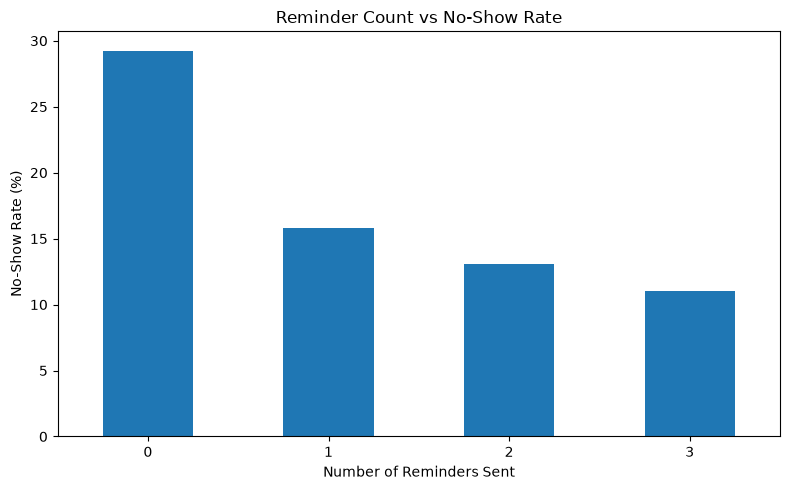

In [24]:
reminder_count_analysis.plot(
    x='reminders_sent',
    y='No_Show_Rate (%)',
    kind='bar',
    figsize=(8, 5),
    legend=False
)

plt.title('Reminder Count vs No-Show Rate')
plt.xlabel('Number of Reminders Sent')
plt.ylabel('No-Show Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Now grouping everything into "No Reminder" vs "Reminder Received" to get one clean comparison.

In [25]:
# How much does reminder type reduce no-show rates compared to no-reminder patients? 



df = df1.copy()

# Identify patients who received no reminder
reminder = (
    df['reminder_type']
    .astype('string')
    .str.strip()
    .str.lower()
)

df['Reminder_Group'] = np.where(
    reminder.isin(['none', 'no reminder', 'no reminders', 'nan', '']),
    'No Reminder',
    'Reminder Received'
)

# Exclude missing no-show flags
df_valid = df.dropna(subset=['no_show_flag']).copy()

# Calculate no-show rates
reminder_effect = (
    df_valid.groupby('Reminder_Group')
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

reminder_effect['No_Show_Rate (%)'] = (
    reminder_effect['No_Shows']
    / reminder_effect['Total_Appointments'] * 100
).round(2)

display(reminder_effect)

,Reminder_Group,Total_Appointments,No_Shows,No_Show_Rate (%)
0,No Reminder,11321,3311,29.25
1,Reminder Received,63679,8273,12.99


In [26]:
rates = reminder_effect.set_index('Reminder_Group')['No_Show_Rate (%)']

no_reminder_rate = rates.get('No Reminder', np.nan)
reminder_rate = rates.get('Reminder Received', np.nan)

if pd.notna(no_reminder_rate) and pd.notna(reminder_rate):
    reduction_pp = no_reminder_rate - reminder_rate

    if no_reminder_rate > 0:
        relative_reduction = (
            reduction_pp / no_reminder_rate
        ) * 100
    else:
        relative_reduction = np.nan

    print(f"No-reminder no-show rate: {no_reminder_rate:.2f}%")
    print(f"Reminder-group no-show rate: {reminder_rate:.2f}%")
    print(f"Difference: {reduction_pp:.2f} percentage points")
    print(f"Relative reduction: {relative_reduction:.2f}%")
else:
    print("Check reminder_type categories; both groups are needed.")

No-reminder no-show rate: 29.25%
Reminder-group no-show rate: 12.99%
Difference: 16.26 percentage points
Relative reduction: 55.59%


**Observations**

- Patients with no reminder have a no-show rate of 29.25%. With any reminder it is 12.99%, which is 16.26 percentage points lower, a relative reduction of about 56%.
- More channels works better: SMS only is 15.77%, SMS + WhatsApp is 13.08% and SMS + WhatsApp + Call is 11.05%. Each extra step takes off a further 2 to 3 points.
- `reminders_sent` lines up one-to-one with reminder type (0, 1, 2, 3), so the second table and chart tell the same story as the first.
- 11,321 appointments (about 15% of the total) still go out with no reminder. If those patients behaved like the reminded group, that would be roughly 1,800 fewer no-shows.
- This is an observed difference, not proof of cause, because the patients who get no reminder may differ in other ways. Still, the gap is far too big to ignore.

### Q2. Does prior no-show history predict future no-show behaviour?

In [27]:
# Does prior no-show history predict future no-show behaviour? 



df = df1.copy()

# Ensure columns are numeric
df['patient_prior_no_shows'] = pd.to_numeric(
    df['patient_prior_no_shows'], errors='coerce'
)

df['no_show_flag'] = pd.to_numeric(
    df['no_show_flag'], errors='coerce'
)

# Group patients by previous no-show history
df['Prior_No_Show_Group'] = pd.cut(
    df['patient_prior_no_shows'],
    bins=[-np.inf, 0, 1, 2, np.inf],
    labels=[
        'No previous no-shows',
        '1 previous no-show',
        '2 previous no-shows',
        '3+ previous no-shows'
    ]
)

# Calculate current no-show rate
history_analysis = (
    df.dropna(subset=['Prior_No_Show_Group', 'no_show_flag'])
    .groupby('Prior_No_Show_Group', observed=False)
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        Current_No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

history_analysis['No_Show_Rate (%)'] = (
    history_analysis['Current_No_Shows']
    / history_analysis['Total_Appointments'] * 100
).round(2)

display(history_analysis)

,Prior_No_Show_Group,Total_Appointments,Current_No_Shows,No_Show_Rate (%)
0,No previous no-shows,65039,9549,14.68
1,1 previous no-show,8784,1723,19.62
2,2 previous no-shows,1021,262,25.66
3,3+ previous no-shows,156,50,32.05


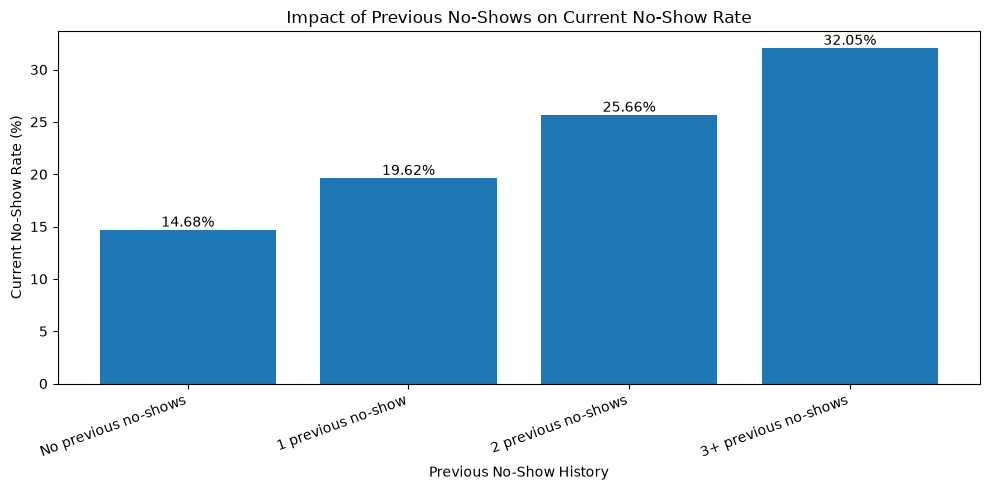

In [28]:


plt.figure(figsize=(10, 5))

bars = plt.bar(
    history_analysis['Prior_No_Show_Group'].astype(str),
    history_analysis['No_Show_Rate (%)']
)

plt.title('Impact of Previous No-Shows on Current No-Show Rate')
plt.xlabel('Previous No-Show History')
plt.ylabel('Current No-Show Rate (%)')
plt.xticks(rotation=20, ha='right')

# Display percentages on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:.2f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

In [29]:
no_history_rate = history_analysis.loc[
    history_analysis['Prior_No_Show_Group'] == 'No previous no-shows',
    'No_Show_Rate (%)'
].iloc[0]

prior_history = history_analysis[
    history_analysis['Prior_No_Show_Group'] != 'No previous no-shows'
]

prior_history_count = prior_history['Total_Appointments'].sum()
prior_history_noshows = prior_history['Current_No_Shows'].sum()

prior_history_rate = (
    prior_history_noshows / prior_history_count * 100
    if prior_history_count > 0 else np.nan
)

print(f"No previous no-shows: {no_history_rate:.2f}%")
print(f"At least one previous no-show: {prior_history_rate:.2f}%")

print(
    f"Difference: {prior_history_rate - no_history_rate:.2f} "
    "percentage points"
)

No previous no-shows: 14.68%
At least one previous no-show: 20.43%
Difference: 5.75 percentage points


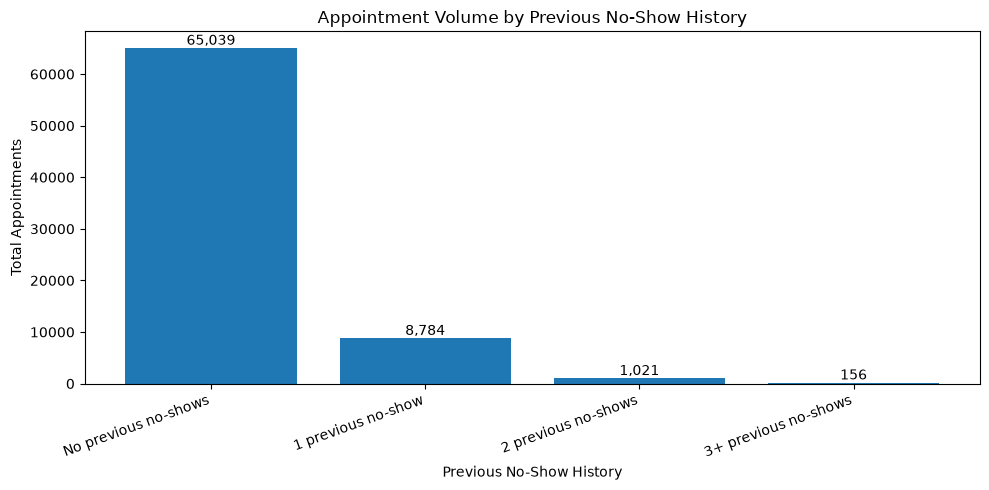

In [30]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    history_analysis['Prior_No_Show_Group'].astype(str),
    history_analysis['Total_Appointments']
)

plt.title('Appointment Volume by Previous No-Show History')
plt.xlabel('Previous No-Show History')
plt.ylabel('Total Appointments')
plt.xticks(rotation=20, ha='right')

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{int(height):,}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

**Observations**

- Yes, and the pattern is clean: 14.68% for patients with no previous no-shows, 19.62% with one, 25.66% with two and 32.05% with three or more. The rate goes up with every extra missed visit.
- Patients with at least one earlier no-show miss 20.43% of the time, which is 5.75 points higher than patients with a clean record.
- The catch is coverage. Only about 9,961 appointments (13%) belong to patients with any prior no-show, and the 3+ group is tiny (156). Roughly 82% of all no-shows (9,549 of 11,584) come from patients with a clean history, so history alone cannot catch most of them.
- It works well as one signal among several, not as the only rule.

### Q3. Do Apollo members and repeat patients show better attendance than non-members and first-time patients?

In [31]:
# Do Apollo members and repeat patients show better attendance than non-members and first-time patients?



df = df1.copy()

membership_analysis = (
    df.groupby('apollo_member', dropna=False)
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

membership_analysis['Attended_Appointments'] = (
    membership_analysis['Total_Appointments'] - membership_analysis['No_Shows']
)

membership_analysis['No_Show_Rate (%)'] = (
    membership_analysis['No_Shows'] /
    membership_analysis['Total_Appointments'] * 100
).round(2)

membership_analysis['Attendance_Rate (%)'] = (
    membership_analysis['Attended_Appointments'] /
    membership_analysis['Total_Appointments'] * 100
).round(2)

display(membership_analysis)

,apollo_member,Total_Appointments,No_Shows,Attended_Appointments,No_Show_Rate (%),Attendance_Rate (%)
0,No,58225,9530,48695,16.37,83.63
1,Yes,16775,2054,14721,12.24,87.76


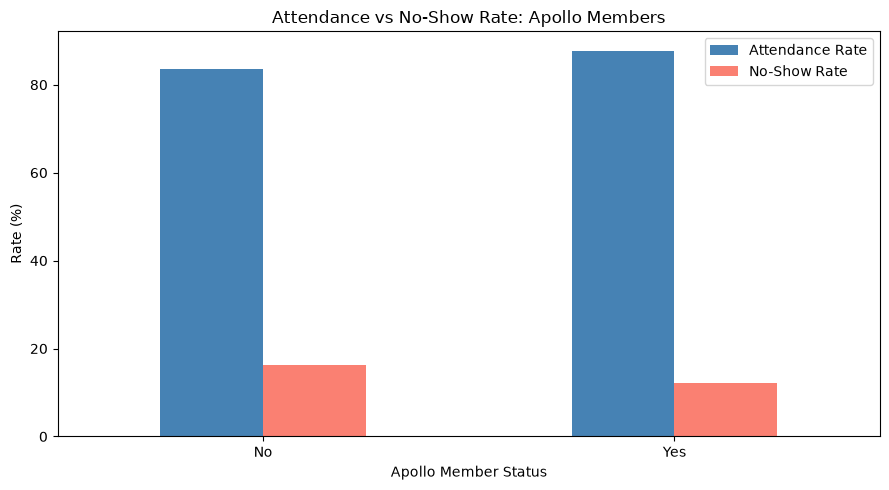

In [32]:
membership_plot = membership_analysis.dropna(subset=['apollo_member']).copy()

membership_plot['Membership'] = membership_plot['apollo_member'].astype(str)

ax = membership_plot.plot(
    x='Membership',
    y=['Attendance_Rate (%)', 'No_Show_Rate (%)'],
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'salmon']
)

ax.set_title('Attendance vs No-Show Rate: Apollo Members')
ax.set_xlabel('Apollo Member Status')
ax.set_ylabel('Rate (%)')
ax.legend(['Attendance Rate', 'No-Show Rate'])
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [33]:
patient_type_analysis = (
    df.groupby('is_first_visit', dropna=False)
    .agg(
        Total_Appointments=('appointment_id', 'count'),
        No_Shows=('no_show_flag', 'sum')
    )
    .reset_index()
)

# is_first_visit is stored as 1 / 0
patient_type_analysis['Patient_Type'] = patient_type_analysis[
    'is_first_visit'
].map({
    1: 'First-time Patients',
    0: 'Repeat Patients'
})

patient_type_analysis['Attended_Appointments'] = (
    patient_type_analysis['Total_Appointments'] -
    patient_type_analysis['No_Shows']
)

patient_type_analysis['Attendance_Rate (%)'] = (
    patient_type_analysis['Attended_Appointments'] /
    patient_type_analysis['Total_Appointments'] * 100
).round(2)

patient_type_analysis['No_Show_Rate (%)'] = (
    patient_type_analysis['No_Shows'] /
    patient_type_analysis['Total_Appointments'] * 100
).round(2)

display(patient_type_analysis)

,is_first_visit,Total_Appointments,No_Shows,Patient_Type,Attended_Appointments,Attendance_Rate (%),No_Show_Rate (%)
0,0,64553,5452,Repeat Patients,59101,91.55,8.45
1,1,10447,6132,First-time Patients,4315,41.30,58.70


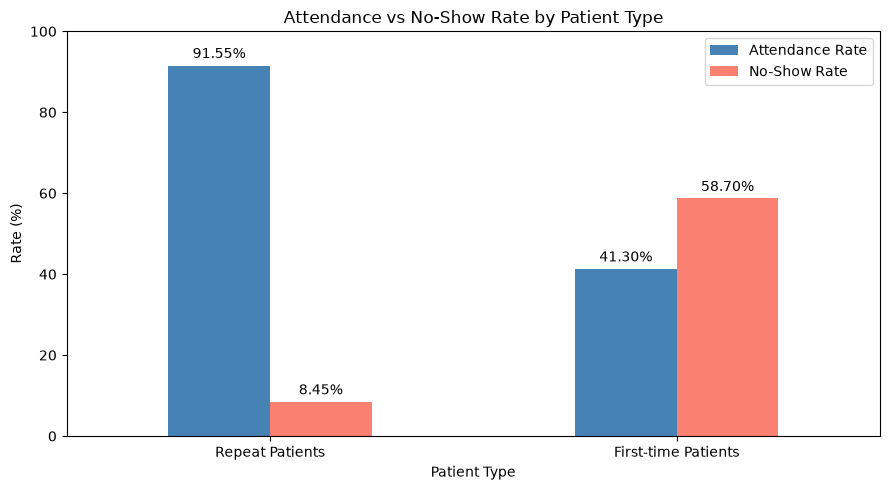

In [34]:


patient_plot = patient_type_analysis.dropna(
    subset=['Patient_Type']
).copy()

ax = patient_plot.plot(
    x='Patient_Type',
    y=['Attendance_Rate (%)', 'No_Show_Rate (%)'],
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'salmon']
)

ax.set_title('Attendance vs No-Show Rate by Patient Type')
ax.set_xlabel('Patient Type')
ax.set_ylabel('Rate (%)')
ax.set_ylim(0, 100)
ax.legend(['Attendance Rate', 'No-Show Rate'])
ax.tick_params(axis='x', rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.tight_layout()
plt.show()

**Observations**

- **Members vs non-members:** members attend more (87.76% attendance, 12.24% no-show) than non-members (83.63% attendance, 16.37% no-show), a gap of about 4 points. Members are 16,775 of the 75,000 appointments.
- **Repeat vs first-time:** this is the biggest gap in the whole analysis. Repeat patients have a no-show rate of 8.45% (91.55% attendance), while first-time patients have 58.70% (only 41.30% attendance).
- First-time patients are only about 14% of appointments but account for roughly 53% of all no-shows (6,132 of 11,584). More than half of the no-show problem sits with people who have never visited before.
- Both loyalty indicators point the same way. Patients who already have a relationship with Apollo show up, and new patients are the leak.

---
## 5. Patient and Demographic Segmentation

### Q1. How do age group, gender and chronic condition status influence no-show likelihood?

In [35]:
# Exclude appointments with unknown no-show outcomes
df_analysis = df1[df1["no_show_flag"].isin([0, 1])].copy()

# Factors to analyze
columns = {
    "age_group": "Age Group",
    "patient_gender": "Gender",
    "patient_chronic_condition": "Chronic Condition"
}

for column, title in columns.items():

    result = df_analysis.groupby(column, dropna=False).agg(
        Total_Appointments=("no_show_flag", "count"),
        No_Shows=("no_show_flag", "sum")
    )

    result["No_Show_Rate_%"] = (
        result["No_Shows"] / result["Total_Appointments"] * 100
    ).round(2)

    print(f"\nNo-Show Analysis by {title}")
    display(result.sort_values("No_Show_Rate_%", ascending=False))


No-Show Analysis by Age Group


,Total_Appointments,No_Shows,No_Show_Rate_%
age_group,,,
Adult (31-45),15627,2731,17.48
Young Adult (19-30),10337,1797,17.38
Middle-aged (46-60),15355,2491,16.22
Teen (13-18),6583,939,14.26
Senior (60+),14968,2036,13.60
Child (0-12),12130,1590,13.11



No-Show Analysis by Gender


,Total_Appointments,No_Shows,No_Show_Rate_%
patient_gender,,,
Female,38787,6029,15.54
Male,36213,5555,15.34



No-Show Analysis by Chronic Condition


,Total_Appointments,No_Shows,No_Show_Rate_%
patient_chronic_condition,,,
Asthma,9388,1520,16.19
Heart Disease,9445,1494,15.82
NaN,28038,4314,15.39
Diabetes,9283,1421,15.31
Hypertension,9394,1417,15.08
Hypothyroidism,9452,1418,15.00


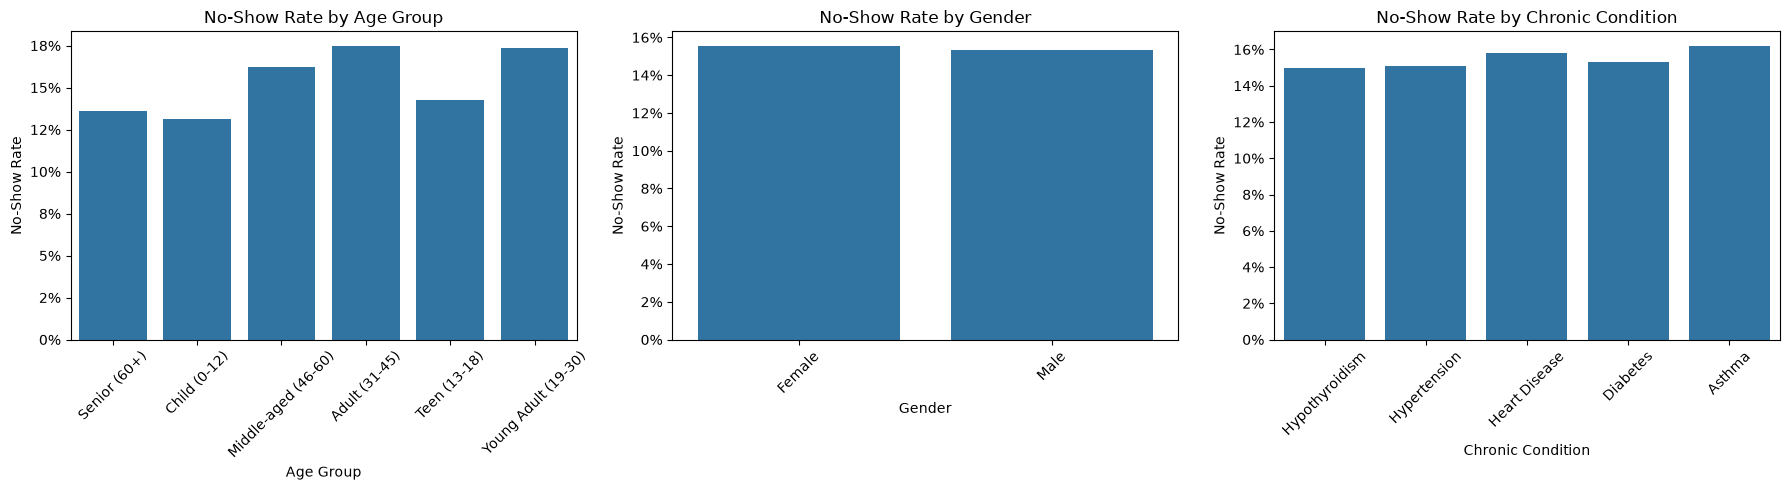

In [36]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (column, title) in zip(axes, columns.items()):

    sns.barplot(
        data=df_analysis,
        x=column,
        y="no_show_flag",
        errorbar=None,
        ax=ax
    )

    ax.set_title(f"No-Show Rate by {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("No-Show Rate")
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"{y:.0%}")
    )
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


**Observations**

- **Age group:** Adults (31-45) at 17.48% and Young Adults (19-30) at 17.38% have the highest no-show rates. Seniors (13.60%) and Children (13.11%) have the lowest. Working-age adults skip appointments more, and children and seniors probably come accompanied by someone, but the data can't confirm that.
- **Gender:** Female 15.54% vs Male 15.34%. The difference is just 0.2 points, so gender doesn't matter here.
- **Chronic condition:** all groups fall between 15.00% (Hypothyroidism) and 16.19% (Asthma). Patients with no chronic condition are at 15.39%. Having a chronic condition doesn't change attendance in any meaningful way.
- The `NaN` row in the chronic condition table is actually the "None" category (28,038 appointments with no chronic condition). pandas reads the text "None" as a missing value, but as per the brief it just means not applicable.
- Of the three, only age shows a real difference, and it is still modest compared with reminders or first-visit status.

### Q2. Which visit reasons are most common and are some associated with higher dropout?

In [37]:
# Exclude appointments with unknown no-show outcomes
df_analysis = df1[df1["no_show_flag"].isin([0, 1])].copy()

# Count appointments and no-shows by visit reason
visit_analysis = df_analysis.groupby("visit_reason", dropna=False).agg(
    total_appointments=("no_show_flag", "count"),
    total_no_shows=("no_show_flag", "sum")
)

# Calculate no-show rate
visit_analysis["no_show_rate_pct"] = (
    visit_analysis["total_no_shows"]
    / visit_analysis["total_appointments"] * 100
).round(2)

# Sort by appointment volume
visit_analysis = visit_analysis.sort_values(
    "total_appointments", ascending=False
)

display(visit_analysis)

,total_appointments,total_no_shows,no_show_rate_pct
visit_reason,,,
Follow-up,8807,1298,14.74
Routine Checkup,8637,1309,15.16
Chronic Condition Management,8380,1266,15.11
Digestive Problem,8245,1297,15.73
Fever & Infection,7041,1095,15.55
Joint Pain,6664,1082,16.24
Respiratory Issue,6590,1020,15.48
Injury,6087,949,15.59
Eye Care,2959,444,15.01


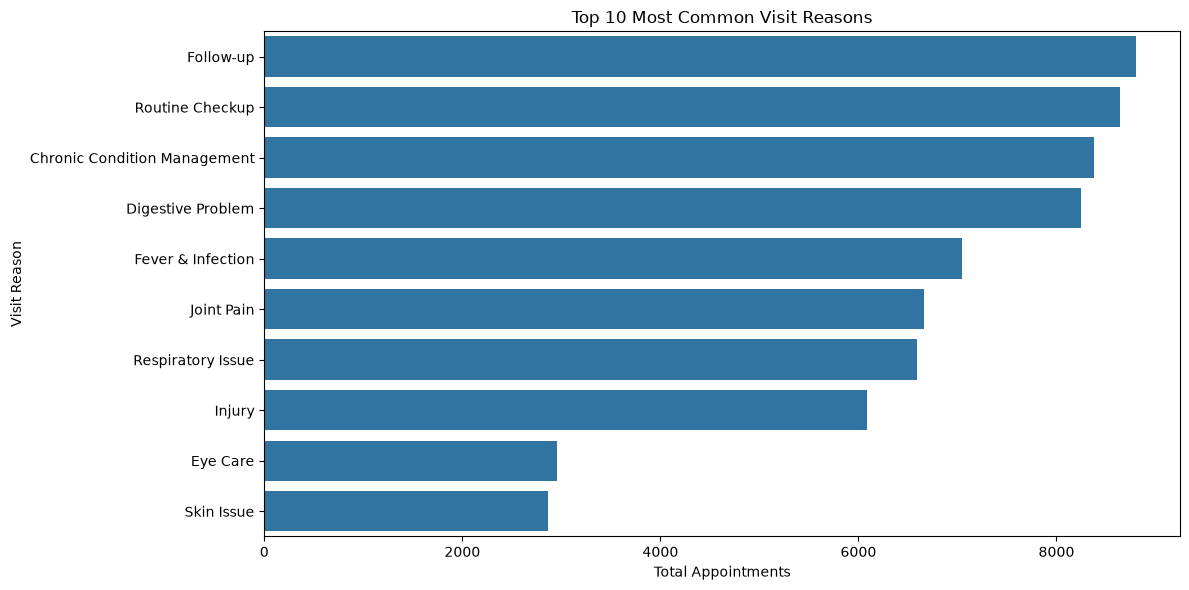

In [38]:
# Most common visit reasons
top_reasons = visit_analysis.head(10).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_reasons,
    x="total_appointments",
    y="visit_reason"
)

plt.title("Top 10 Most Common Visit Reasons")
plt.xlabel("Total Appointments")
plt.ylabel("Visit Reason")
plt.tight_layout()
plt.show()

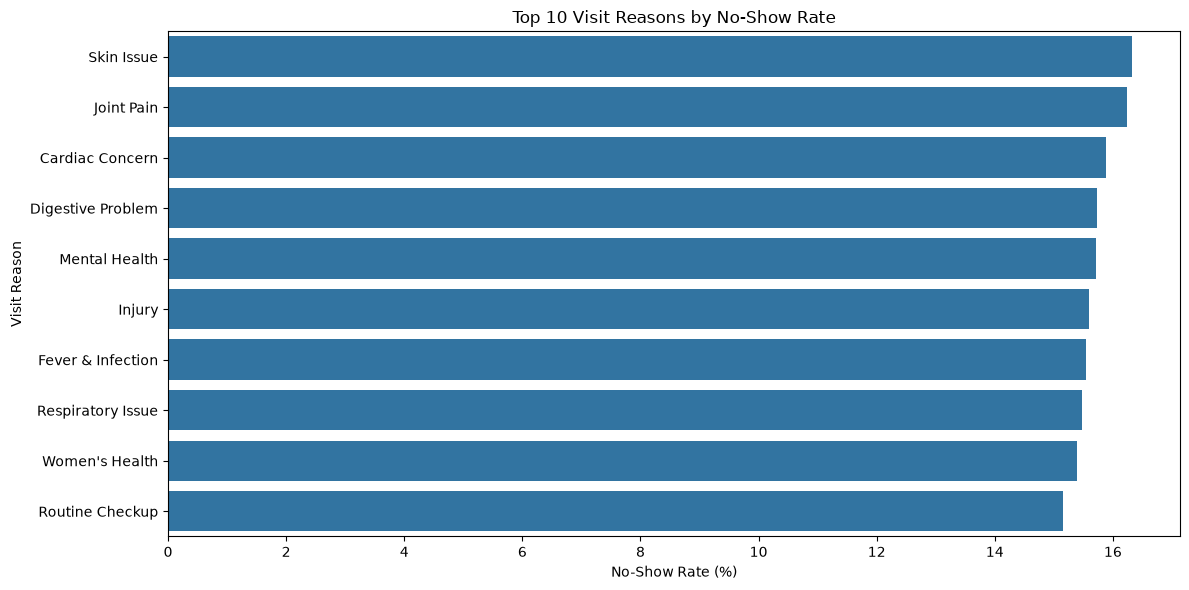

In [39]:

# Rank visit reasons by no-show rate
highest_no_show = visit_analysis.sort_values(
    "no_show_rate_pct", ascending=False
).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(
    data=highest_no_show.head(10),
    x="no_show_rate_pct",
    y="visit_reason"
)

plt.title("Top 10 Visit Reasons by No-Show Rate")
plt.xlabel("No-Show Rate (%)")
plt.ylabel("Visit Reason")
plt.tight_layout()
plt.show()


**Observations**

- The most common reasons are Follow-up (8,807), Routine Checkup (8,637), Chronic Condition Management (8,380), Digestive Problem (8,245) and Fever & Infection (7,041). Child Health is the smallest with 741.
- No-show rates by reason stay in a narrow band, from 14.17% (Child Health) to 16.32% (Skin Issue). Joint Pain (16.24%) and Cardiac Concern (15.88%) are also near the top.
- A spread of about 2 points is small. Visit reason is not a useful way to predict dropout. For example, Mental Health visits are at 15.72% even though the Psychiatry specialty is at 23.79%, so the specialty effect isn't coming from the visit reason.

### Q3. What does the patient age distribution look like within Paediatrics, Gynaecology and Psychiatry?

In [40]:
# Q3 What does the patient age distribution look like within specialties like Paediatrics, Gynaecology, and Psychiatry? 

# Select the required specialties
selected_specialties = [
    "Paediatrics",
    "Gynaecology",
    "Psychiatry"
]

specialty_df = df1[
    df1["specialty"].str.strip().str.lower().isin(
        [s.lower() for s in selected_specialties]
    )
].copy()

# Remove missing ages
specialty_df = specialty_df.dropna(subset=["patient_age"])

# Check available specialty names and patient counts
display(
    specialty_df.groupby("specialty")["patient_age"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(1)
)


,count,mean,median,min,max
specialty,,,,,
Gynaecology,4113,41.7,42.0,1,85
Paediatrics,6382,9.3,9.0,1,18
Psychiatry,2989,42.0,42.0,1,85


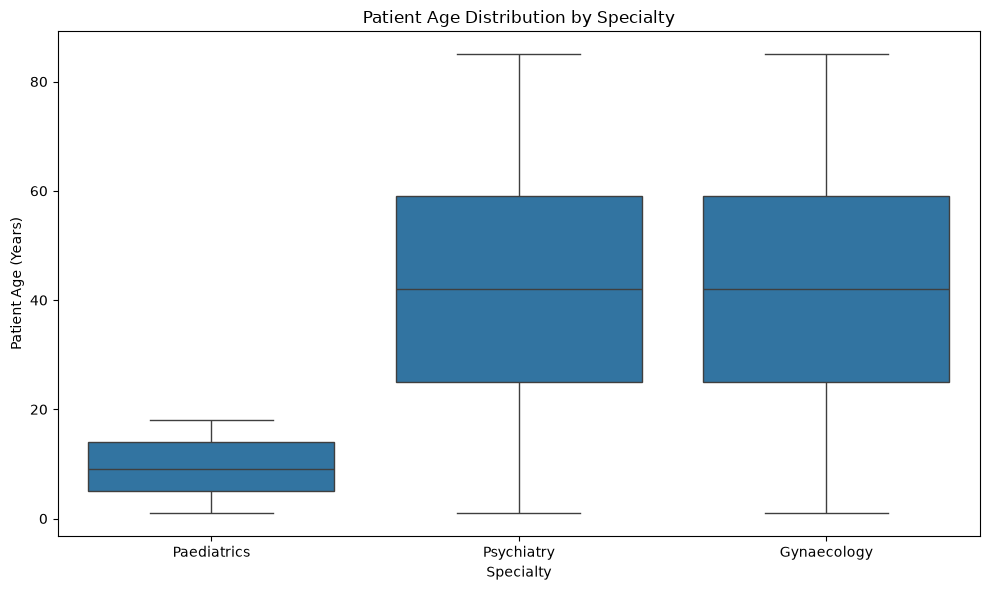

In [41]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=specialty_df,
    x="specialty",
    y="patient_age"
)

plt.title("Patient Age Distribution by Specialty")
plt.xlabel("Specialty")
plt.ylabel("Patient Age (Years)")
plt.tight_layout()
plt.show()


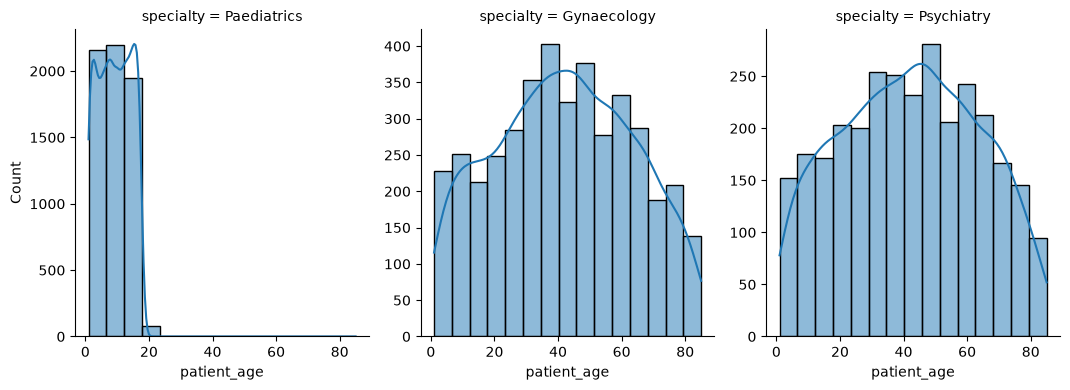

In [42]:

sns.displot(
    data=specialty_df,
    x="patient_age",
    col="specialty",
    col_order=selected_specialties,
    bins=15,
    kde=True,
    facet_kws={"sharex": True, "sharey": False},
    height=4,
    aspect=0.9
)

plt.show()


**Observations**

- **Paediatrics:** ages 1 to 18, average 9.3 and median 9. This is a purely child and teen specialty, as expected.
- **Gynaecology:** average 41.7, median 42, covering ages 1 to 85. Most patients are in the 30 to 55 range.
- **Psychiatry:** average 42.0, median 42, also 1 to 85, with a broad spread and a peak at roughly 35 to 55.
- Gynaecology and Psychiatry both serve a wide adult age range. Because their median age is about 42, these are largely working-age patients, which fits with the higher no-show rates seen for working-age groups.
- Data quality flag: Gynaecology and Psychiatry both have patients aged 1 year, which is not realistic for those specialties. It is probably an entry error or a feature of how the data was generated, and worth confirming with the data team.

---
## 6. Financial Performance

### Q1. How much revenue is being lost to no-shows?

Revenue columns are zero for no-shows, so the loss is estimated using the listed consultation fee of each no-show appointment.

In [43]:
# Financial Performance 

#Q1 How much revenue is being lost to no-shows? 

# Select appointments marked as no-shows
no_show_df = df1[df1["no_show_flag"] == 1].copy()

# Calculate estimated revenue lost
estimated_lost_revenue = no_show_df["consultation_fee"].sum()

# Calculate the number of no-show appointments
total_no_shows = len(no_show_df)

# Calculate average consultation fee
average_fee = no_show_df["consultation_fee"].mean()

print("Total No-Show Appointments:", total_no_shows)
print("Average Consultation Fee:", round(average_fee, 2))
print("Estimated Revenue Lost: ₹", round(estimated_lost_revenue, 2))
print("Estimated Revenue Lost (Lakhs): ₹", round(estimated_lost_revenue / 100000, 2), "Lakhs")

Total No-Show Appointments: 11584
Average Consultation Fee: 1702.82
Estimated Revenue Lost: ₹ 19725460
Estimated Revenue Lost (Lakhs): ₹ 197.25 Lakhs


,Category,Appointment_Count,Estimated_Revenue
0,Completed Appointments,55275,73893798
1,No-Show Appointments,11584,19725460


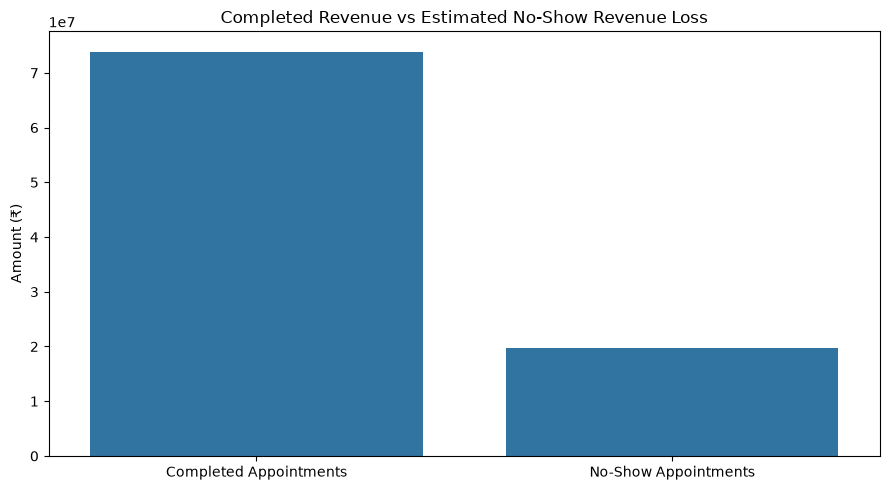

In [44]:

revenue_comparison = pd.DataFrame({
    "Category": ["Completed Appointments", "No-Show Appointments"],
    "Appointment_Count": [
        (df1["appointment_status"] == "Completed").sum(),
        (df1["no_show_flag"] == 1).sum()
    ],
    "Estimated_Revenue": [
        df1.loc[df1["appointment_status"] == "Completed", "revenue_realized"].sum(),
        df1.loc[df1["no_show_flag"] == 1, "consultation_fee"].sum()
    ]
})

display(revenue_comparison)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=revenue_comparison,
    x="Category",
    y="Estimated_Revenue"
)

plt.title("Completed Revenue vs Estimated No-Show Revenue Loss")
plt.xlabel("")
plt.ylabel("Amount (₹)")
plt.tight_layout()
plt.show()


**Observations**

- 11,584 no-show appointments with an average fee of about ₹1,703 add up to an estimated loss of about **₹1.97 crore (₹197.25 lakh)**.
- For comparison, the revenue actually realised from completed appointments is about ₹7.39 crore. The lost amount is equal to roughly 27% of that, or about 21% of what would have been earned if every no-show had turned up.
- This uses the listed fee, so it is a slightly generous estimate (it ignores discounts and insurance), but it gives the right order of magnitude.

### Q2. How does average revenue vary across specialties and appointment types?

In [45]:
# How does average revenue vary across specialties and appointment types? 


# Consider completed appointments only
completed_df = df1[
    df1["appointment_status"] == "Completed"
].copy()

# Calculate average revenue for each specialty and appointment type
revenue_analysis = completed_df.pivot_table(
    index="specialty",
    columns="appointment_type",
    values="revenue_realized",
    aggfunc="mean"
).round(2)

print("Average Revenue by Specialty and Appointment Type:")
display(revenue_analysis)


Average Revenue by Specialty and Appointment Type:


appointment_type,Home Visit,In-Clinic,Video Consult
specialty,,,
Cardiology,2863.29,1878.64,1573.14
Dermatology,1901.56,1274.97,1087.90
ENT,1752.33,1164.54,992.10
Endocrinology,2644.18,1758.83,1579.26
Gastroenterology,2767.52,1853.60,1575.35
General Physician,925.26,611.14,533.06
Gynaecology,2170.50,1475.18,1262.94
Neurology,3039.42,2013.70,1637.61
Ophthalmology,2179.95,1421.43,1132.76


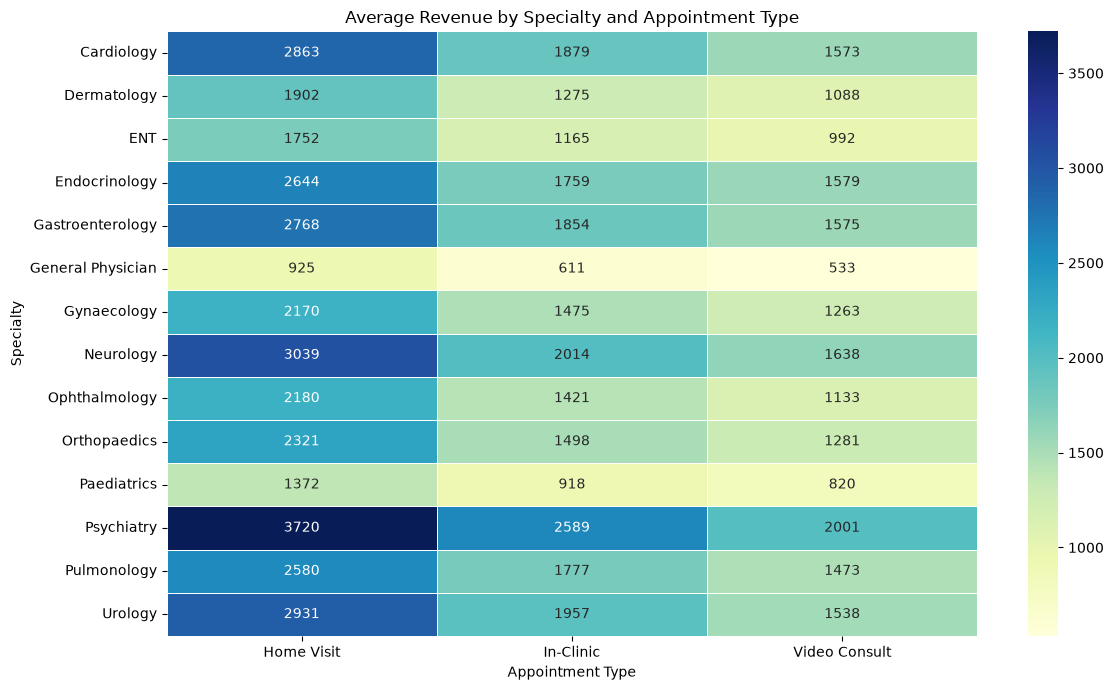

In [46]:

plt.figure(figsize=(12, 7))

sns.heatmap(
    revenue_analysis,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Revenue by Specialty and Appointment Type")
plt.xlabel("Appointment Type")
plt.ylabel("Specialty")
plt.tight_layout()
plt.show()


In [47]:
revenue_long = (
    completed_df.groupby(
        ["specialty", "appointment_type"], dropna=False
    )
    .agg(
        total_appointments=("revenue_realized", "count"),
        average_revenue=("revenue_realized", "mean"),
        total_revenue=("revenue_realized", "sum")
    )
    .round(2)
    .reset_index()
)

display(
    revenue_long.sort_values(
        "average_revenue", ascending=False
    )
)

,specialty,appointment_type,total_appointments,average_revenue,total_revenue
33,Psychiatry,Home Visit,229,3720.49,851993
21,Neurology,Home Visit,470,3039.42,1428528
39,Urology,Home Visit,198,2931.22,580382
0,Cardiology,Home Visit,431,2863.29,1234076
12,Gastroenterology,Home Visit,240,2767.52,664204
9,Endocrinology,Home Visit,186,2644.18,491817
34,Psychiatry,In-Clinic,1460,2588.93,3779839
36,Pulmonology,Home Visit,227,2580.01,585663
27,Orthopaedics,Home Visit,491,2321.43,1139822
24,Ophthalmology,Home Visit,269,2179.95,586407


**Observations**

- Home Visit has the highest average revenue in every specialty, then In-Clinic, then Video Consult. The order is the same everywhere.
- Psychiatry earns the most per appointment (₹3,720 home visit, ₹2,589 in-clinic, ₹2,001 video), followed by Neurology and Urology. General Physician earns the least (about ₹925 home, ₹611 in-clinic, ₹533 video).
- Home visits bring in the most per appointment but are also the most likely to be a no-show (25.39%), so each missed home visit costs more than a missed clinic visit.
- General Physician is the biggest specialty by volume but the lowest earner per visit, so it depends on volume, while specialist visits depend on keeping each slot filled.

### Q3. Which cities generate the most revenue and what is the payment mode mix?

In [48]:
# Which cities generate the most revenue and what is the payment mode mix? 

# Filter completed appointments
completed_df = df1[
    df1["appointment_status"] == "Completed"
].copy()

# Revenue generated by city
city_revenue = (
    completed_df.groupby("city", dropna=False)
    .agg(
        total_revenue=("revenue_realized", "sum"),
        total_appointments=("appointment_id", "count")
    )
    .sort_values("total_revenue", ascending=False)
)

city_revenue["revenue_lakhs"] = (
    city_revenue["total_revenue"] / 100000
).round(2)

print("Top 10 Cities by Revenue:")
display(city_revenue.head(10))

Top 10 Cities by Revenue:


,total_revenue,total_appointments,revenue_lakhs
city,,,
Bengaluru,9990616,6405,99.91
Delhi,9958247,7834,99.58
Mumbai,8989613,7318,89.90
Hyderabad,7503245,5496,75.03
Chennai,7188473,5132,71.88
Kolkata,6543084,4280,65.43
Pune,4734139,3179,47.34
Ahmedabad,3956890,2607,39.57
Lucknow,3177444,2254,31.77


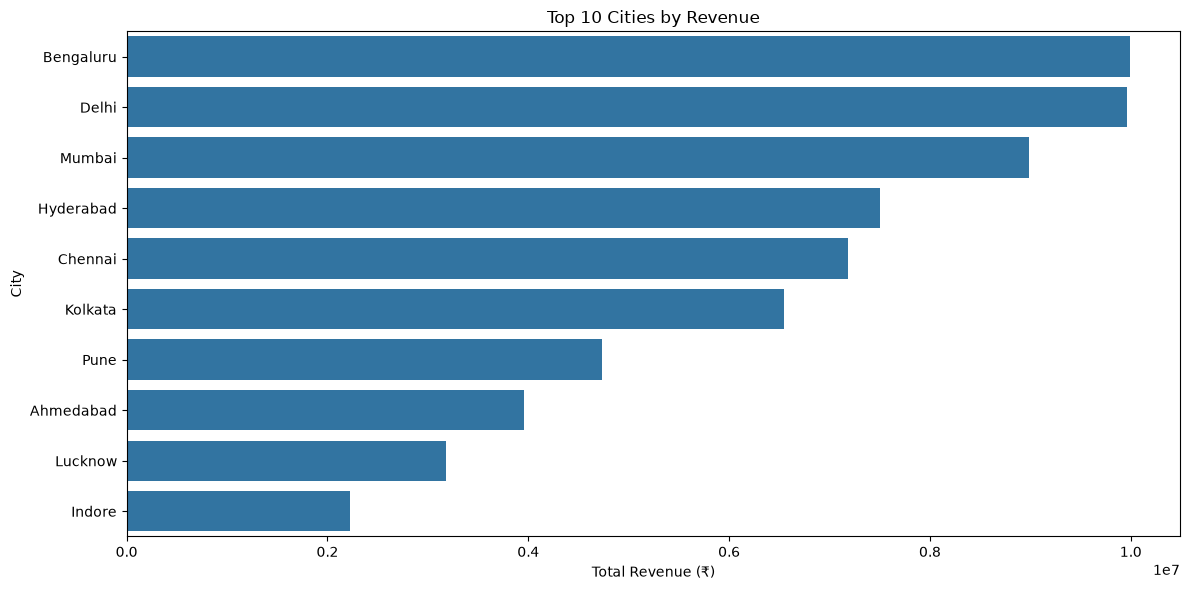

In [49]:

top_cities = city_revenue.head(10).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_cities,
    x="total_revenue",
    y="city"
)

plt.title("Top 10 Cities by Revenue")
plt.xlabel("Total Revenue (₹)")
plt.ylabel("City")
plt.tight_layout()
plt.show()


In [50]:

payment_analysis = (
    completed_df.groupby("payment_mode", dropna=False)
    .agg(
        transaction_count=("appointment_id", "count"),
        total_revenue=("revenue_realized", "sum")
    )
)

payment_analysis["appointment_share_pct"] = (
    payment_analysis["transaction_count"]
    / payment_analysis["transaction_count"].sum() * 100
).round(2)

payment_analysis["revenue_share_pct"] = (
    payment_analysis["total_revenue"]
    / payment_analysis["total_revenue"].sum() * 100
).round(2)

payment_analysis = payment_analysis.sort_values(
    "transaction_count", ascending=False
)

print("Payment Mode Mix:")
display(payment_analysis)


Payment Mode Mix:


,transaction_count,total_revenue,appointment_share_pct,revenue_share_pct
payment_mode,,,,
Insurance,11641,5744092,21.06,7.77
Debit Card,7353,11513741,13.30,15.58
Net Banking,7349,11477401,13.30,15.53
Apollo Pay,7324,11524032,13.25,15.60
UPI,7259,11242692,13.13,15.21
Credit Card,7213,11299512,13.05,15.29
Cash,7136,11092328,12.91,15.01


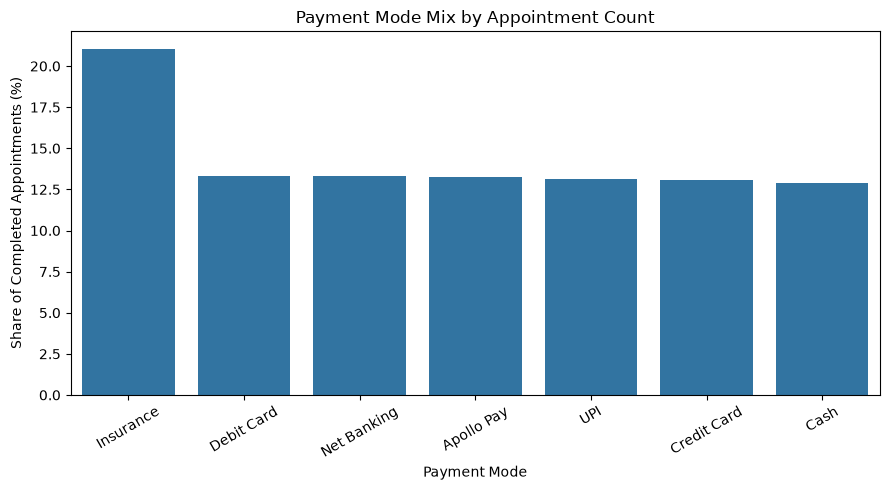

In [51]:

payment_counts = payment_analysis.reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=payment_counts,
    x="payment_mode",
    y="appointment_share_pct"
)

plt.title("Payment Mode Mix by Appointment Count")
plt.xlabel("Payment Mode")
plt.ylabel("Share of Completed Appointments (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Observations**

- **Cities:** Bengaluru (₹99.91 lakh) and Delhi (₹99.58 lakh) are almost level at the top, then Mumbai (₹89.90 lakh), Hyderabad (₹75.03 lakh) and Chennai (₹71.88 lakh). The top three cities bring in about 39% of the total.
- Delhi has more completed appointments than Bengaluru (7,834 vs 6,405) but slightly lower revenue, because Bengaluru earns more per appointment (about ₹1,560 vs ₹1,271).
- **Payment mix:** Insurance is the largest single mode at 21.06% of completed appointments, but only 7.77% of revenue. The other six modes (Debit Card, Net Banking, Apollo Pay, UPI, Credit Card, Cash) are each close to 13% of appointments and 15% of revenue.
- Cash is the smallest mode at 12.91%, so digital payments are well established. There is no single dominant payment mode among the non-insurance ones.
- The low revenue share for Insurance is because `revenue_realized` adds up to exactly the patient out-of-pocket amount. The part paid by insurers (roughly ₹1.24 crore) is not counted in this revenue figure, so the true value of insured visits is higher than shown.

### Q4. How does insurance coverage affect what patients pay out of pocket?

In [52]:
# How does insurance coverage affect what patients pay out of pocket? 

# Filter completed appointments
completed_df = df1[
    df1["appointment_status"] == "Completed"
].copy()

# Summarize patient payments by insurance coverage
insurance_analysis = (
    completed_df.groupby("insurance_coverage", dropna=False)
    .agg(
        total_appointments=("appointment_id", "count"),
        avg_insurance_covered=("insurance_covered_amount", "mean"),
        avg_out_of_pocket=("patient_out_of_pocket", "mean"),
        median_out_of_pocket=("patient_out_of_pocket", "median"),
        total_out_of_pocket=("patient_out_of_pocket", "sum")
    )
    .round(2)
)

print("Insurance Coverage and Patient Payments:")
display(insurance_analysis)



Insurance Coverage and Patient Payments:


,total_appointments,avg_insurance_covered,avg_out_of_pocket,median_out_of_pocket,total_out_of_pocket
insurance_coverage,,,,,
No,37523,0.00,1562.82,1500.0,58641720
Yes,17752,697.17,859.18,607.0,15252078


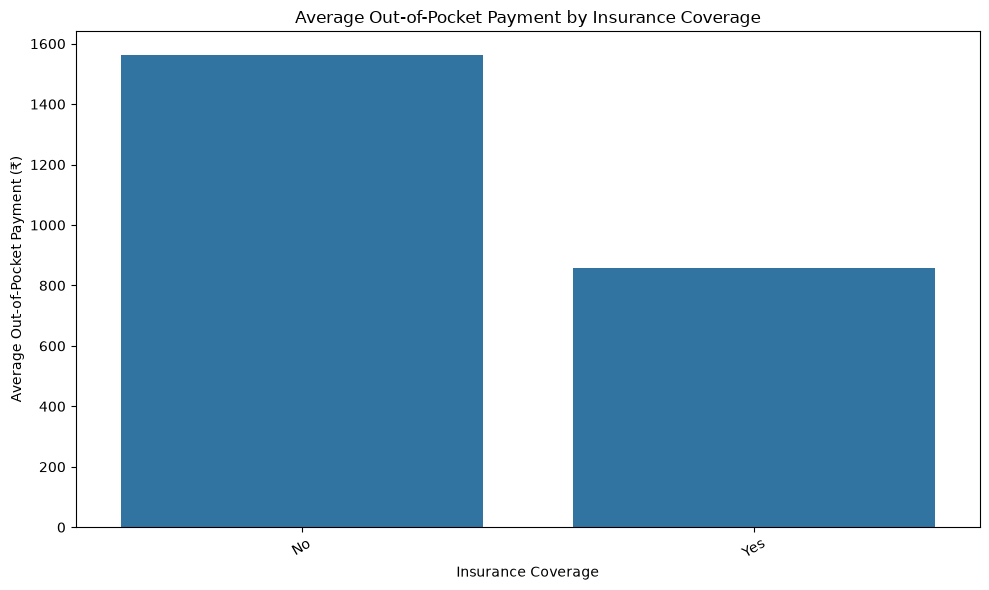

In [53]:

insurance_plot = insurance_analysis.reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=insurance_plot,
    x="insurance_coverage",
    y="avg_out_of_pocket"
)

plt.title("Average Out-of-Pocket Payment by Insurance Coverage")
plt.xlabel("Insurance Coverage")
plt.ylabel("Average Out-of-Pocket Payment (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


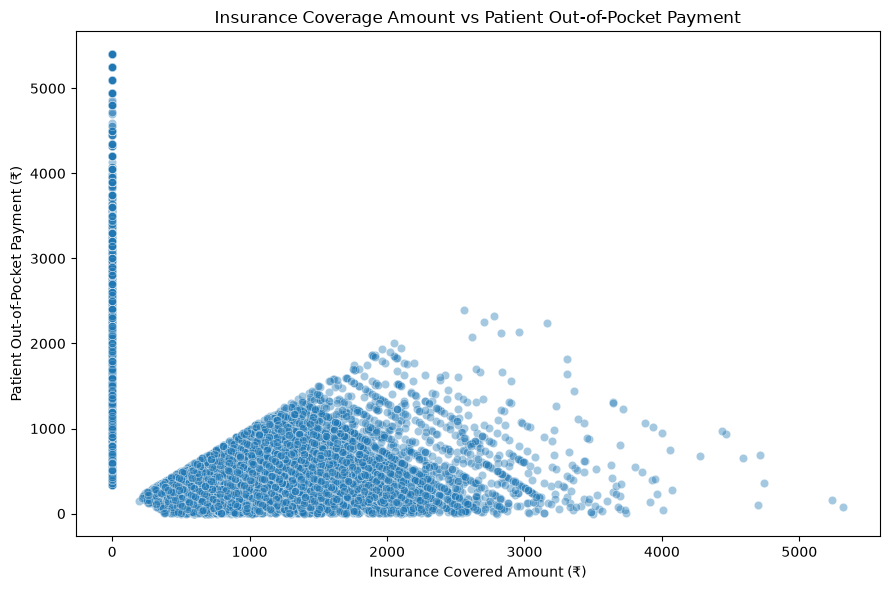

In [54]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=completed_df,
    x="insurance_covered_amount",
    y="patient_out_of_pocket",
    alpha=0.4
)

plt.title("Insurance Coverage Amount vs Patient Out-of-Pocket Payment")
plt.xlabel("Insurance Covered Amount (₹)")
plt.ylabel("Patient Out-of-Pocket Payment (₹)")
plt.tight_layout()
plt.show()


**Observations**

- 17,752 of the 55,275 completed appointments (about 32%) are covered by insurance.
- Insured patients pay an average of ₹859 out of pocket against ₹1,563 for uninsured patients, which is about 45% less. The median gap is bigger: ₹607 vs ₹1,500, about 60% less.
- On average the insurer pays ₹697 per insured visit.
- The scatter plot shows that the more the insurer covers, the less the patient pays, as expected, so insurance directly lowers the barrier to a visit.

---
## 7. Doctor Utilisation and Service Quality

All metrics in this section are for Completed appointments only, since the values are null for everything else.

### Q1. Which specialties have the highest and lowest doctor utilisation rates?

In [55]:
# Doctor Utilisation and Service Quality

# Which specialties have the highest and lowest doctor utilisation rates? 

# Use completed appointments where utilisation data is available
util_df = df1[
    (df1["appointment_status"] == "Completed")
    & (df1["doctor_utilization_pct"].notna())
].copy()

# Calculate average doctor utilisation by specialty
utilization_analysis = (
    util_df.groupby("specialty", dropna=False)
    .agg(
        avg_utilization_pct=("doctor_utilization_pct", "mean"),
        appointment_count=("appointment_id", "count"),
        doctor_count=("doctor_id", "nunique")
    )
    .round(2)
    .sort_values("avg_utilization_pct", ascending=False)
)

display(utilization_analysis)

print("Highest utilisation specialty:")
display(utilization_analysis.head(1))

print("Lowest utilisation specialty:")
display(utilization_analysis.tail(1))


,avg_utilization_pct,appointment_count,doctor_count
specialty,,,
Gastroenterology,77.26,1972,11
Endocrinology,77.15,1504,10
Cardiology,76.81,3507,20
Gynaecology,76.80,3134,18
Paediatrics,76.66,4900,27
Neurology,76.63,3899,22
General Physician,76.59,14981,85
Urology,76.44,1729,9
Orthopaedics,76.43,4189,23


Highest utilisation specialty:


,avg_utilization_pct,appointment_count,doctor_count
specialty,,,
Gastroenterology,77.26,1972,11


Lowest utilisation specialty:


,avg_utilization_pct,appointment_count,doctor_count
specialty,,,
Psychiatry,76.18,1958,13


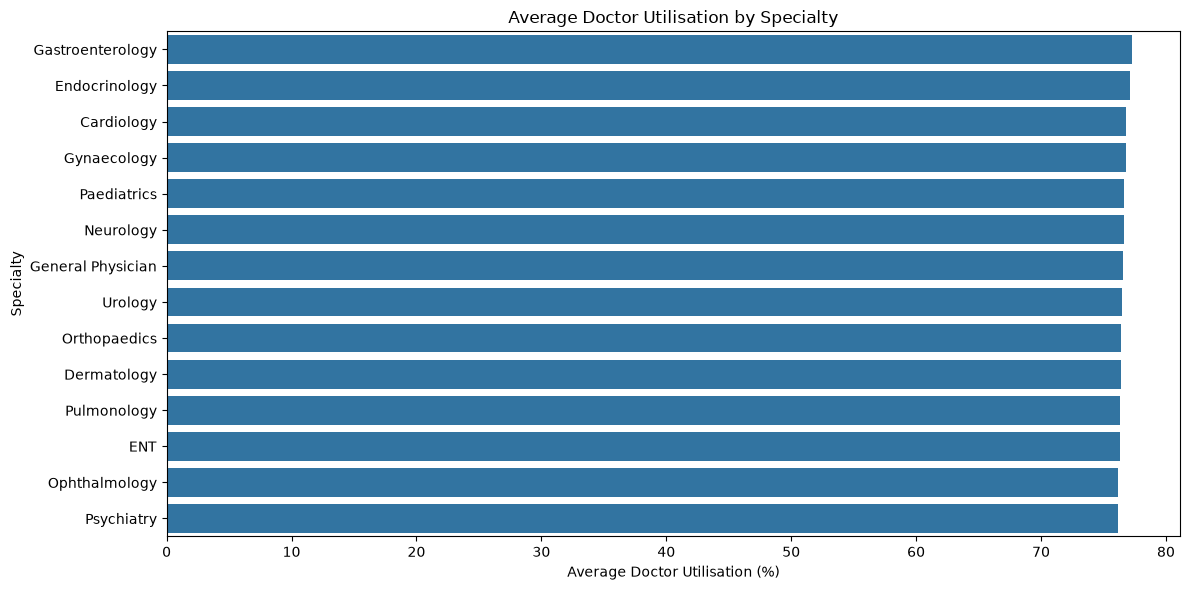

In [56]:

util_plot = utilization_analysis.reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=util_plot,
    x="avg_utilization_pct",
    y="specialty"
)

plt.title("Average Doctor Utilisation by Specialty")
plt.xlabel("Average Doctor Utilisation (%)")
plt.ylabel("Specialty")
plt.tight_layout()
plt.show()


**Observations**

- Gastroenterology is the highest at 77.26% and Psychiatry is the lowest at 76.18%.
- The whole range is just about 1 percentage point. Every specialty sits at roughly 76 to 77%, which is why the bars in the chart all look almost the same.
- No specialty is clearly under-used or over-stretched on this metric, so utilisation by specialty is not where the opportunity is. Psychiatry having the lowest utilisation and also the highest no-show rate (23.79%) is still worth noticing.

### Q2. How long are patients waiting and does it vary by specialty or time of day?

In [57]:
# How long are patients waiting and does it vary by specialty or time of day? 

# Filter completed appointments with recorded waiting times
wait_df = df1[
    (df1["appointment_status"] == "Completed")
    & (df1["wait_time_minutes"].notna())
].copy()

# Overall waiting-time summary
print("Overall Waiting Time Summary:")
display(
    wait_df["wait_time_minutes"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print("Average waiting time:",
      round(wait_df["wait_time_minutes"].mean(), 2), "minutes")

Overall Waiting Time Summary:


count     55275.00
mean         11.55
median        8.00
min           0.00
max          90.00
Name: wait_time_minutes, dtype: float64

Average waiting time: 11.55 minutes


In [58]:

specialty_wait = (
    wait_df.groupby("specialty", dropna=False)
    .agg(
        average_wait_minutes=("wait_time_minutes", "mean"),
        median_wait_minutes=("wait_time_minutes", "median"),
        appointment_count=("appointment_id", "count")
    )
    .round(2)
    .sort_values("average_wait_minutes", ascending=False)
)

display(specialty_wait)


,average_wait_minutes,median_wait_minutes,appointment_count
specialty,,,
Ophthalmology,12.02,8.0,2349
Urology,11.91,8.0,1729
Dermatology,11.77,8.0,5347
Orthopaedics,11.70,8.0,4189
Neurology,11.64,8.0,3899
Gynaecology,11.62,8.0,3134
Cardiology,11.59,8.0,3507
General Physician,11.53,8.0,14981
Endocrinology,11.46,8.0,1504


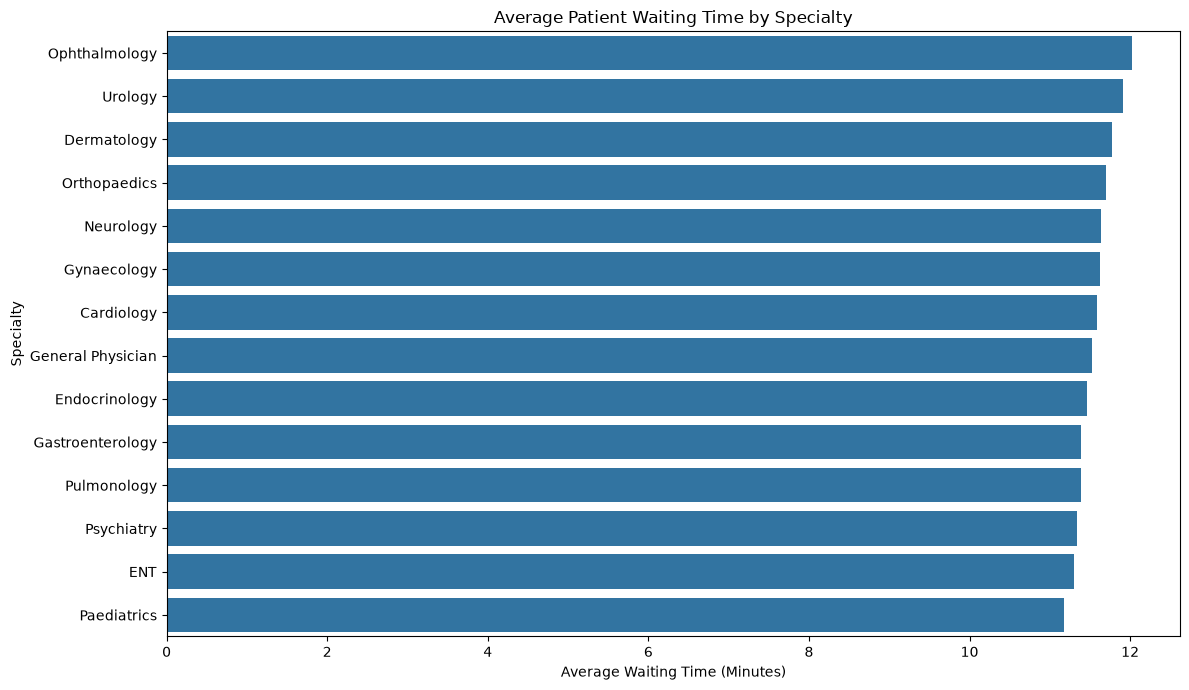

In [59]:

plt.figure(figsize=(12, 7))

sns.barplot(
    data=specialty_wait.reset_index(),
    x="average_wait_minutes",
    y="specialty"
)

plt.title("Average Patient Waiting Time by Specialty")
plt.xlabel("Average Waiting Time (Minutes)")
plt.ylabel("Specialty")
plt.tight_layout()
plt.show()


In [60]:

time_wait = (
    wait_df.groupby("time_of_day", dropna=False)
    .agg(
        average_wait_minutes=("wait_time_minutes", "mean"),
        median_wait_minutes=("wait_time_minutes", "median"),
        appointment_count=("appointment_id", "count")
    )
    .round(2)
    .sort_values("average_wait_minutes", ascending=False)
)

display(time_wait)


,average_wait_minutes,median_wait_minutes,appointment_count
time_of_day,,,
Afternoon,11.55,8.0,17270
Evening,11.55,8.0,10718
Morning,11.55,8.0,27287


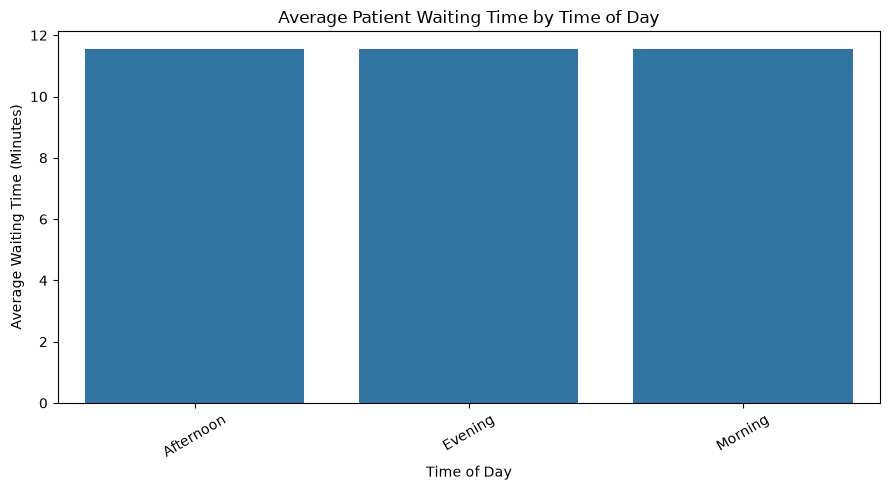

In [61]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=time_wait.reset_index(),
    x="time_of_day",
    y="average_wait_minutes"
)

plt.title("Average Patient Waiting Time by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Average Waiting Time (Minutes)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


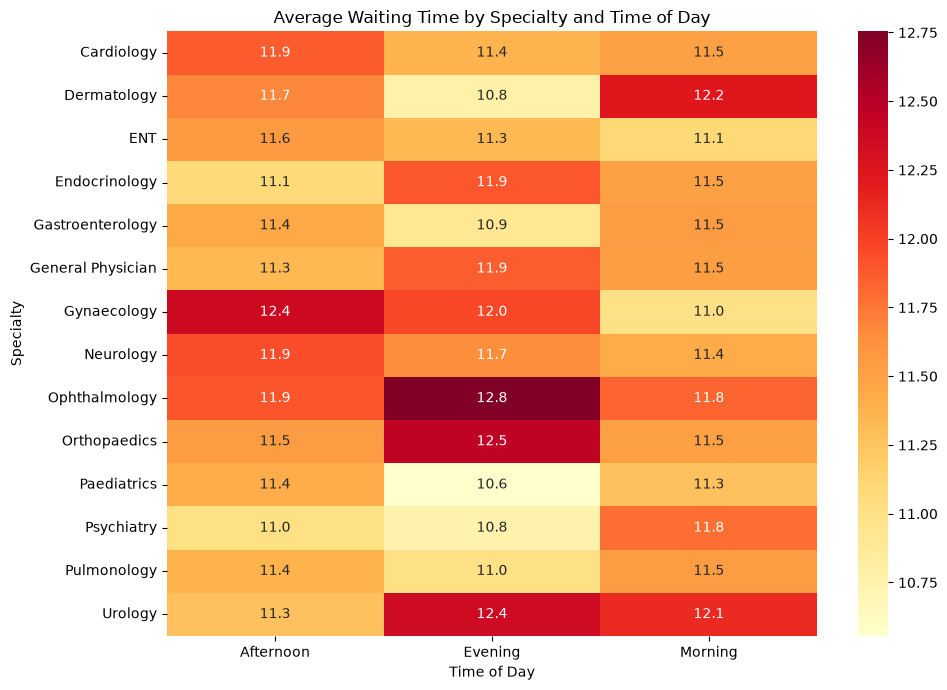

In [62]:

wait_heatmap = wait_df.pivot_table(
    index="specialty",
    columns="time_of_day",
    values="wait_time_minutes",
    aggfunc="mean"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    wait_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Average Waiting Time by Specialty and Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Specialty")
plt.tight_layout()
plt.show()


**Observations**

- The average wait is 11.55 minutes but the median is only 8, and the longest is 90 minutes. A small number of very long waits pull the average up.
- **By specialty:** Ophthalmology is the longest at 12.02 minutes and Paediatrics is the shortest at 11.18. A difference of under a minute.
- **By time of day:** Morning, Afternoon and Evening all average 11.55 minutes, with the same median of 8. There is no time-of-day effect.
- The heatmap shows the same thing, with no specialty and time combination standing out. Waiting time is fairly even across the system, and the focus should be on the few very long waits rather than on particular specialties or slots.

### Q3. Is there a relationship between consultation duration and patient satisfaction?

In [63]:
# Is there a relationship between consultation duration and patient satisfaction? 


# Keep completed appointments with valid duration and satisfaction scores
duration_df = df1[
    (df1["appointment_status"] == "Completed")
    & (df1["consultation_duration_min"].notna())
    & (df1["patient_satisfaction_score"].notna())
].copy()

# Summary statistics
display(
    duration_df[
        ["consultation_duration_min", "patient_satisfaction_score"]
    ].describe().round(2)
)

# Calculate Pearson correlation
correlation = duration_df[
    ["consultation_duration_min", "patient_satisfaction_score"]
].corr().iloc[0, 1]

print("Correlation between consultation duration and satisfaction:",
      round(correlation, 3))

,consultation_duration_min,patient_satisfaction_score
count,55275.00,55275.00
mean,18.44,4.07
std,8.63,0.64
min,5.00,1.00
25%,12.00,3.60
50%,17.00,4.10
75%,25.00,4.60
max,48.00,5.00


Correlation between consultation duration and satisfaction: -0.004


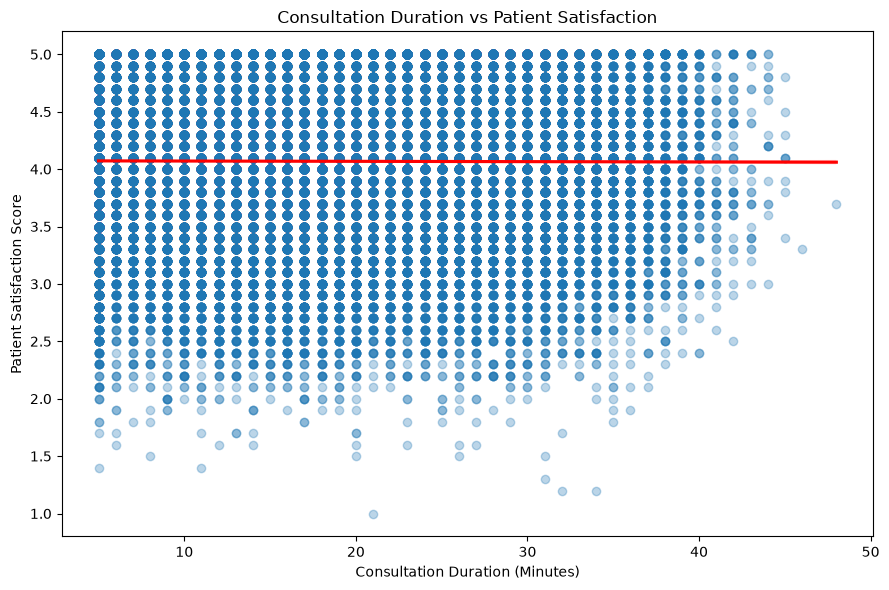

In [64]:

plt.figure(figsize=(9, 6))

sns.regplot(
    data=duration_df,
    x="consultation_duration_min",
    y="patient_satisfaction_score",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Consultation Duration vs Patient Satisfaction")
plt.xlabel("Consultation Duration (Minutes)")
plt.ylabel("Patient Satisfaction Score")
plt.tight_layout()
plt.show()


In [65]:

duration_df["duration_group"] = pd.cut(
    duration_df["consultation_duration_min"],
    bins=[0, 10, 20, 30, 45, float("inf")],
    labels=["0–10 min", "11–20 min", "21–30 min",
            "31–45 min", "45+ min"],
    include_lowest=True
)

duration_analysis = (
    duration_df.groupby("duration_group", observed=False)
    .agg(
        appointment_count=("patient_satisfaction_score", "count"),
        average_satisfaction=("patient_satisfaction_score", "mean"),
        median_satisfaction=("patient_satisfaction_score", "median")
    )
    .round(2)
)

display(duration_analysis)


,appointment_count,average_satisfaction,median_satisfaction
duration_group,,,
0–10 min,11146,4.07,4.1
11–20 min,23298,4.07,4.1
21–30 min,14891,4.07,4.1
31–45 min,5938,4.07,4.1
45+ min,2,3.50,3.5


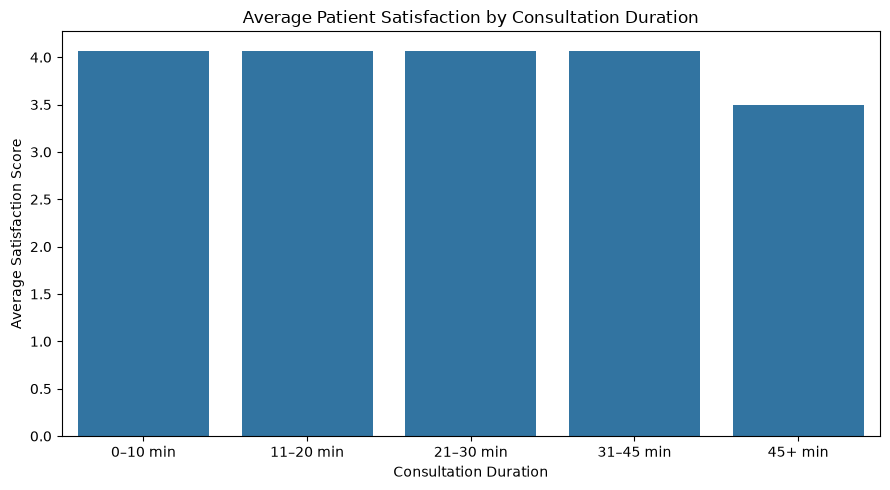

In [66]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=duration_df,
    x="duration_group",
    y="patient_satisfaction_score",
    errorbar=None
)

plt.title("Average Patient Satisfaction by Consultation Duration")
plt.xlabel("Consultation Duration")
plt.ylabel("Average Satisfaction Score")
plt.tight_layout()
plt.show()


**Observations**

- Average consultation length is 18.44 minutes and average satisfaction is 4.07 out of 5.
- The correlation between the two is -0.004, which is essentially zero. The regression line in the scatter plot is flat.
- Grouped by duration, satisfaction is 4.07 for every band from 0 to 45 minutes. (The 45+ minute band has only 2 appointments, so it can be ignored.)
- A longer consultation doesn't make patients happier and a short one doesn't make them less happy. Satisfaction must be driven by something else, such as doctor behaviour, outcome or the overall experience.

### Q4. How does doctor experience relate to the fee charged (joined with the doctors table)?

The appointments table and the doctors table both have a `consultation_fee` column, so after the merge they appear as `consultation_fee_x` (appointment) and `consultation_fee_y` (doctor's listed fee). The doctor's fee is used here.

In [67]:
# How does doctor experience relate to the fee charged (join with doctors dim)? 

# Join appointments with doctor details
doctor_fee_df = df1.merge(
    doctors_df,
    on="doctor_id",
    how="left"
)

doctor_fee_df.head()

,appointment_id,patient_id,doctor_id,appointment_date,appointment_day,appointment_day_of_week,appointment_month,appointment_quarter,appointment_year,appointment_hour,...,city_y,state_y,hospital_name_y,consultation_fee_y,rating,total_reviews,available_days,avg_slot_duration_min,accepts_insurance,teleconsult_enabled
0,APPT5000001,PAT117608,DOC1035,2023-11-15,Wednesday,2,11,Q4,2023,15,...,Bengaluru,Karnataka,Apollo Clinic Jayanagar,2700,4.6,55,Mon-Fri,30,Yes,No
1,APPT5000002,PAT128732,DOC1049,2023-03-13,Monday,0,3,Q1,2023,9,...,Pune,Maharashtra,Apollo Spectra Pune,1400,4.7,1912,Mon-Fri,15,No,Yes
2,APPT5000003,PAT137532,DOC1033,2022-02-07,Monday,0,2,Q1,2022,17,...,Bengaluru,Karnataka,Apollo Spectra Koramangala,600,4.7,589,Mon-Fri,10,Yes,No
3,APPT5000004,PAT113284,DOC1288,2023-11-20,Monday,0,11,Q4,2023,17,...,Delhi,Delhi,Apollo Hospital Sarita Vihar,1500,4.9,2281,Mon-Fri,20,Yes,Yes
4,APPT5000005,PAT107443,DOC1064,2024-02-02,Friday,4,2,Q1,2024,19,...,Coimbatore,Tamil Nadu,Apollo Clinic Coimbatore,2000,4.9,393,Mon-Wed-Fri-Sat,20,No,No


In [68]:
print(doctor_fee_df.columns.tolist())

['appointment_id', 'patient_id', 'doctor_id', 'appointment_date', 'appointment_day', 'appointment_day_of_week', 'appointment_month', 'appointment_quarter', 'appointment_year', 'appointment_hour', 'appointment_minute', 'time_slot', 'time_of_day', 'booking_date', 'booking_lead_days', 'booking_channel', 'appointment_type', 'specialty_x', 'city_x', 'state_x', 'hospital_name_x', 'patient_age', 'age_group', 'patient_gender', 'patient_city_tier', 'patient_chronic_condition', 'apollo_member', 'membership_type', 'reminder_type', 'reminders_sent', 'patient_prior_visits', 'patient_prior_no_shows', 'is_first_visit', 'repeat_visit', 'visit_reason', 'appointment_status', 'no_show', 'no_show_flag', 'cancellation_reason', 'consultation_fee_x', 'discount_pct', 'actual_fee_charged', 'insurance_coverage', 'insurance_provider', 'insurance_covered_amount', 'patient_out_of_pocket', 'revenue_realized', 'payment_mode', 'wait_time_minutes', 'consultation_duration_min', 'patient_satisfaction_score', 'doctor_uti

In [69]:
experience_fee = (
    doctor_fee_df
    .groupby("experience_years")["consultation_fee_y"]
    .mean()
    .reset_index()
)

experience_fee.columns = [
    "Experience (Years)",
    "Average Consultation Fee"
]

experience_fee

,Experience (Years),Average Consultation Fee
0,2,1325.531070
1,3,1162.830350
2,4,1394.431487
3,5,1276.149176
4,6,1638.945578
5,7,1369.018205
6,8,1437.604291
7,9,1122.581874
8,10,1667.304286
9,11,1298.455779


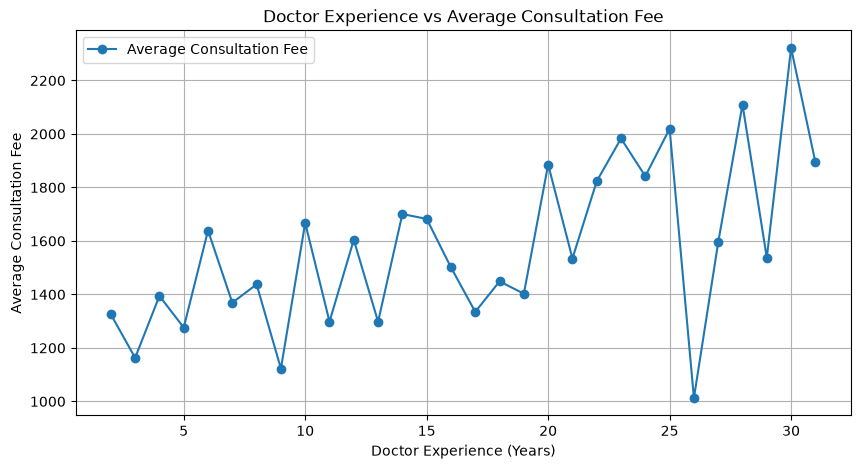

In [70]:
experience_fee.plot(
    x="Experience (Years)",
    y="Average Consultation Fee",
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Doctor Experience vs Average Consultation Fee")
plt.xlabel("Doctor Experience (Years)")
plt.ylabel("Average Consultation Fee")
plt.grid(True)
plt.show()

**Observations**

- There is a clear upward trend. Doctors with 2 to 5 years of experience charge roughly ₹1,150 to ₹1,400 on average, while those with 25 or more years charge about ₹1,900 to ₹2,300.
- The line is jagged, though. For example the 26-year group falls to about ₹1,013 and the 30-year group jumps to about ₹2,321. These swings are likely because some experience-year groups contain very few doctors, and the specialty mix affects the average (Psychiatry and Neurology are priced higher than General Physician).
- Experience is a factor in the fee, but specialty is just as important. A fuller view would look at fee by experience within each specialty.

---
## 8. Key Findings and Recommendations

### Key findings

| Area | What the data shows |
|---|---|
| Volume | Flat at about 25,000 appointments a year, with a steady Q4 peak and a June to August dip |
| Outcomes | 73.70% completed, 15.45% no-show, 7.72% cancelled, 3.13% still scheduled |
| Reminders | No reminder: 29.25% no-show. Any reminder: 12.99%. Three-channel reminder: 11.05% |
| First-time patients | 58.70% no-show vs 8.45% for repeat patients. About 53% of all no-shows |
| Appointment type | Home Visit 25.39%, Video 20.41%, In-Clinic 11.80% |
| Specialty | Psychiatry 23.79% and Dermatology 20.55% highest. Neurology 10.31% lowest |
| Timing | Evening, weekends and bookings made more than a week ahead all show higher dropout |
| Prior no-shows | Rate rises from 14.68% to 32.05% as past no-shows go from 0 to 3+ |
| Membership | Members 12.24% vs non-members 16.37% |
| Money | About ₹1.97 crore lost to no-shows vs about ₹7.39 crore realised |
| Service quality | Wait time (about 11.5 min), utilisation (76 to 77%) and satisfaction (4.07) look the same across specialties, times and consultation lengths |
| Not drivers | Gender, chronic condition and visit reason barely change no-show rates |

### Recommendations

1. **Make a reminder mandatory for every booking.** About 15% of appointments still go out with no reminder, and those patients no-show at 29.25%. Moving everyone to at least SMS + WhatsApp, and adding a call for risky bookings, is the cheapest fix and could prevent roughly 1,800 no-shows (about ₹31 lakh at the average fee) based on this data.

2. **Treat first-time patients as a priority group.** They are 14% of bookings but over half of the no-shows. Use a welcome message, a confirmation call a day before, easy directions or a one-tap reschedule, and consider a small commitment such as a refundable booking fee.

3. **Add extra confirmation for Home Visit and Video Consult bookings.** Their no-show rates (25.39% and 20.41%) are about double in-clinic. Home visits also carry the highest revenue per appointment, so a missed one costs the most. A same-morning confirmation and a quick "reschedule" link would help.

4. **Cut down long booking gaps.** Dropout rises from about 14% for 1 to 3 day bookings to over 19% for bookings made 15 to 30 days out. For far-ahead bookings, send a reconfirmation closer to the date and offer to move the slot earlier if one opens up.

5. **Manage high-risk slots and specialties with controlled overbooking.** Evenings, weekends, Psychiatry, Dermatology and ENT have the highest dropout. A waitlist or limited overbooking for these slots would protect doctor time. Psychiatry in particular needs a follow-up routine (reminder calls, flexible rescheduling).

6. **Use prior no-shows as a risk flag.** Patients with one or more earlier no-shows go from 14.68% to 20% to 32%. Flag them in the booking system for a personal call or a confirmation step, while remembering that this alone catches only a minority of no-shows.

7. **Push bookings to the Apollo App and grow membership.** The app is the biggest channel (45%) and has the lowest no-show rate (13.73%), and members attend better than non-members (12.24% vs 16.37%). Walk-in bookings (20.26%) need a follow-up process, such as a reminder as soon as the booking is made at the counter.

8. **Do not spend effort on gender, chronic condition or visit reason.** They show almost no difference in no-show rate. Focus on reminders, lead time, appointment type and patient history.

9. **Plan around seasonality.** Staff up for Q4 and January, and run reminder drives and patient outreach during the June to August dip.

10. **Look into the data issues I noticed.** Patients aged 1 in Gynaecology and Psychiatry, `revenue_realized` equalling only the out-of-pocket amount (so insurer payments are not in the revenue numbers), and the very high first-visit no-show rate should be confirmed with the data owners before decisions are finalised.

### Conclusion

Most of the no-show problem comes from a few identifiable groups: patients with no reminder, first-time patients, home and video consults, and long-lead bookings. These are all things Apollo can act on directly. Fixing reminders and first-visit follow-up alone would address a large part of the roughly ₹2 crore being lost, without needing any change to doctor capacity.